# 복강경 담낭절제술 이미지 분할 (Semantic Segmentation) 

이번 장은 복강경 담낭절제술(laparoscopic cholecystectomy) 장면의 13개 클래스를 픽셀단위로 영역 분할한 데이터셋으로 DeepLabV3+ 모델을 학습/검증/테스트합니다.<br/>간(liver)·담낭(gallbladder)·지방(fat)·도구가 한 화면에 섞이고, 담낭관(cystic duct)·간정맥(hepatic vein)은 픽셀이 1%도 안 되는 경우가 많은 Class-Imbalanced Dataset 구성입니다.

### 13개 클래스
| 번호 | 클래스명 |
|---|---|
| 0 | 배경 (background) |
| 1 | 복벽 (abdominal wall) |
| 2 | 간 (liver) |
| 3 | 위장관 (GI tract) |
| 4 | 지방 (fat) |
| 5 | 겸자 (grasper) |
| 6 | 결합조직 (connective tissue) |
| 7 | 혈액 (blood) |
| 8 | 담낭관 (cystic duct) |
| 9 | L-hook (L-hook) |
| 10 | 담낭 (gallbladder) |
| 11 | 간정맥 (hepatic vein) |
| 12 | 간인대 (liver ligament) |

## 📌 이 노트북에서 배우는 것

이 노트북은 "분류 → 객체 검출 → 세그멘테이션"으로 이어지는 컴퓨터 비전 과제 중 가장 세밀한 **세그멘테이션(segmentation)** 을 직접 돌려 보는 실습입니다. 수술 영상 한 장을 넣으면, 모델이 **모든 픽셀에 "이건 간", "이건 겸자"처럼 이름표(클래스)를 붙여서** 돌려줍니다. 쉽게 말해 **모델이 하는 색칠공부**입니다.

### 학습 목표
1. 세그멘테이션의 정답(**마스크**)이 어떻게 생겼고, 어떻게 색으로 시각화하는지 이해합니다.
2. DeepLabV3+ 구조(**ResNet 인코더 → ASPP → 디코더**)를 그림과 코드로 읽습니다.
3. 클래스 불균형이 심한 데이터에서 **클래스 가중치 + 교차엔트로피 + Dice 손실**을 함께 쓰는 이유를 이해합니다.
4. **Dice · IoU** 로 모델을 평가하고, 클래스별 점수를 해석합니다.
5. 학습된 가중치로 추론하고 **입력 / 정답 / 예측**을 나란히 비교합니다.

### 세 가지 비전 과제 비교

| 과제 | 모델이 내놓는 것 | 이 데이터에서의 예 |
|---|---|---|
| 분류 (classification) | 이미지 **전체**에 라벨 1개 | "담낭절제술 장면입니다" |
| 객체 검출 (detection) | 객체마다 **사각형 박스** + 라벨 | "겸자가 이 사각형 안에 있습니다" |
| **세그멘테이션 (segmentation)** | **픽셀마다** 라벨 | "겸자 모양 그대로 칠합니다" |

### 전체 흐름

| 단계 | 하는 일 | 꼭 실행해야 하나요? |
|---|---|---|
| 1~3 | 데이터 zip 설정, 패키지 설치, 다운로드·압축 해제 | 필수 |
| 4 | 정답 마스크를 색으로 칠해 **데이터를 눈으로 확인** | 필수 (뒤에서 쓰는 변수·함수를 여기서 만듭니다) |
| 5 | **DeepLabV3+ 모델** 정의 | 필수 |
| 6 | 모델 **학습** (T4 기준 약 10분) | 선택 (건너뛰어도 7·8번은 실행됩니다) |
| 7 | 테스트 세트로 **정량 평가** (Dice, IoU) | 권장 |
| 8 | 예제 이미지로 **추론·시각화** | 권장 |

> 💡 **셀은 위에서 아래로 순서대로 실행합니다.** 앞 셀에서 만든 변수와 함수를 뒤 셀이 가져다 쓰기 때문입니다. 런타임을 다시 시작하면 처음부터 다시 실행해야 합니다.

### 셀 사이의 연결 고리 (어떤 셀이 무엇을 만들어 주는가)

| 만들어 주는 셀 | 정의되는 것 | 이후 쓰이는 곳 |
|---|---|---|
| 1번 설정 셀 | `ZIP_URL`, `TASK`, `ZIP_PATH`, `DST` | 다운로드·압축 해제 |
| 3번 마지막 셀 | `ROOT`(데이터 폴더), `DEVICE`(GPU/CPU), `show_img` | 거의 모든 셀 |
| 4번 | `np`, `NUM_CLASSES`, `CLASS_LABEL`, `COLORS`, `IMAGENET_MEAN/STD`, `overlay` | 학습·평가·추론 |
| 5번 | `DeepLabV3Plus` 클래스 | 학습·평가·추론 |
| 6번 (선택) | 학습된 가중치 `runs/best_colab.pt` | 7·8번에서 `WEIGHTS`를 바꿀 때 |

### 데이터는 세 가지로 나뉩니다

| 데이터 | 폴더 | 쓰임새 | 가중치를 수정하는 데 쓰나요? |
|---|---|---|---|
| 학습 (train) | `dataset/train_*` | 6번에서 모델을 학습하고, 클래스 가중치를 계산합니다. | 예 |
| 검증 (val) | `dataset/val_*` | 6번에서 에폭마다 점수를 재어 **가장 좋은 가중치를 고릅니다.** | 아니요 (선택에만 사용) |
| 테스트 (test) | `dataset/test_*` | 7번에서 **최종 성능**을 평가합니다. | 아니요 (학습과 선택 어디에도 쓰지 않음) |

### 텐서 모양을 읽는 법

텐서는 NumPy 배열과 비슷한 다차원 숫자 배열이며, GPU에서 계산할 수 있습니다. 이 노트북에서는 이미지 묶음을 `(B, C, H, W)` = (배치 크기, 채널 수, 높이, 너비) 순서로 표기합니다. 예를 들어 `(4, 3, 288, 512)` 는 "RGB 이미지 4장, 각각 높이 288 × 너비 512"라는 뜻입니다.

### 핵심 용어 미리보기

| 용어 | 한 줄 설명 |
|---|---|
| 클래스 (class) | 픽셀이 속할 수 있는 종류입니다. 여기서는 배경 포함 **13개**입니다. |
| 마스크 (mask) | 픽셀마다 **클래스 번호(0~12)** 를 적어 둔 정답 이미지입니다. |
| 인코더 / 디코더 | 이미지를 **줄이면서 의미를 뽑는** 앞단 / 다시 **키우면서 픽셀 단위로 복원하는** 뒷단입니다. |
| 팽창 합성곱 (dilated conv) | 커널의 칸 사이를 벌려서 **같은 계산량으로 더 넓은 영역**을 보는 합성곱입니다. |
| ASPP | 서로 다른 시야로 같은 특징을 **여러 번 보고 합치는** 모듈입니다. |
| 스킵 연결 (skip connection) | 앞단의 **선명한 정보**를 뒷단으로 직접 전달하는 지름길입니다. |
| 로짓 (logit) | 모델이 클래스마다 내놓는 **점수**입니다. (softmax 하기 전 값) |
| 소프트맥스 (softmax) | 클래스별 점수를 **합이 1인 확률**로 바꾸는 함수입니다. |
| 정규화 (normalize) | 입력 값에서 평균을 빼고 표준편차로 나누어 **값의 범위를 맞추는** 처리입니다. |
| 증강 (augmentation) | 학습 이미지를 무작위로 살짝 변형해서 **데이터의 다양성을 늘리는** 방법입니다. |
| Dice / IoU | 예측 칠과 정답 칠이 **얼마나 겹치는지** 재는 점수입니다. (0~1, 클수록 좋습니다.) |
| 에폭 (epoch) / 배치 (batch) | 학습 데이터를 **한 바퀴** 도는 것 / 한 번에 묶어서 처리하는 **이미지 묶음**입니다. |
| 과적합 (overfitting) | 학습 데이터에만 지나치게 맞춰져서 **새 데이터에서는 성능이 떨어지는** 현상입니다. |
| 체크포인트 (checkpoint) | 학습 도중 또는 최고 시점의 **가중치를 저장한 파일**입니다. |
| 오버레이 (overlay) | 원본 위에 **반투명한 색 마스크**를 겹쳐 그린 그림입니다. |

## 1. 데이터 zip

드라이브에서 해당 zip을 `링크가 있는 모든 사용자`로 공유한 뒤, 링크를 `ZIP_URL`에 넣습니다.

파일이 100MB보다 크면 `wget`이 구글 확인 페이지를 받습니다. 드라이브 링크는 `gdown`, 직접 열리는 주소는 `wget`을 사용합니다.

### 🔎 아래 셀이 하는 일

실제 계산은 하지 않고, **"어디서 받아서, 어디에 풀 것인가"** 를 변수 네 개에 적어 둘 뿐입니다.

| 변수 | 의미 |
|---|---|
| `ZIP_URL` | 데이터 zip의 구글 드라이브 공유 링크입니다. |
| `TASK` | zip을 풀면 생기는 **최상위 폴더 이름**입니다. |
| `ZIP_PATH` | 내려받은 zip 파일을 저장할 위치입니다. |
| `DST` | 압축을 푼 뒤의 데이터 폴더 경로입니다. (`/content/segmentation_medical`) |

> 💡 `f"/content/{TASK}"` 는 **f-string** 입니다. 문자열 안의 `{TASK}` 자리에 변수 값이 들어갑니다.
> 본인의 데이터를 쓰고 싶다면 `ZIP_URL`과 `TASK`만 바꾸면 됩니다. 단, `TASK`는 zip 안의 최상위 폴더 이름과 같아야 합니다.

In [ ]:
# ──────────────── 데이터 zip 위치 설정 ────────────────
# 구글 드라이브 '공유 링크'를 문자열로 적습니다. (공유 설정: 링크가 있는 모든 사용자)
# 본인이 만든 zip을 쓰고 싶다면 이 링크만 바꾸면 됩니다.
ZIP_URL = "https://drive.google.com/file/d/1Ew_Yf3LktMzvtcFfgjsvshXbK-LUfqEl/view?usp=sharing"

# zip 안에 들어 있는 최상위 폴더 이름입니다. 압축을 풀면 /content/<TASK> 폴더가 생깁니다.
TASK = "segmentation_medical"
# 내려받은 zip 파일을 저장할 위치입니다. (/content 는 Colab의 임시 작업 공간이며, 세션이 끝나면 비워집니다.)
ZIP_PATH = "/content/05_medical_segmentation.zip"
# 압축을 푼 뒤 실제 데이터가 들어 있는 폴더 경로입니다.
# f-string 이라서 TASK 값이 끼워져 "/content/segmentation_medical" 이 됩니다.
DST = f"/content/{TASK}"

## 2. 패키지

이 노트북에서 따로 준비할 것은 두 가지뿐입니다. (`torch`, `numpy`, `PIL`, `matplotlib` 등은 Colab에 보통 이미 설치되어 있습니다.)

| 준비물 | 왜 필요한가요? |
|---|---|
| `gdown` | 구글 드라이브의 파일을 내려받는 도구입니다. |
| 한글 폰트 | 이미지 위에 **한글 범례**를 그릴 때 필요합니다. Colab 기본 환경에는 한글 폰트가 없어서, 설치하지 않으면 글자가 `□□□`로 깨집니다. |

> 💡 코드 맨 앞의 `!` 는 "**파이썬이 아니라 터미널(셸) 명령을 실행하라**"는 표시입니다. `pip`, `apt-get`, `unzip` 같은 명령이 여기에 해당합니다.

폰트를 찾는 `hangul_font` 함수는 후보 경로를 **순서대로 시도해서 처음 성공한 폰트를 사용**합니다. 한글 폰트를 하나도 찾지 못하면 `None`을 돌려주고, 이후 범례는 영문 이름으로 그려집니다.

In [ ]:
# [셸 명령] 맨 앞의 ! 는 "파이썬이 아니라 터미널에서 실행하라"는 표시입니다.
# pip install -q gdown : 구글 드라이브 파일을 내려받는 도구 gdown 을 설치합니다. (-q : 설치 로그를 조용히)
!pip install -q gdown

In [ ]:
# ── (1) 한글 폰트 설치 ──────────────────────────────
# apt-get 은 리눅스(우분투)의 프로그램 설치 도구입니다. -qq : 출력을 거의 숨기는 '조용한' 옵션입니다.
# 먼저 설치 가능한 패키지 목록을 최신으로 갱신하고,
!apt-get -qq update
# 한글 폰트 두 종류(Noto Sans CJK, 나눔고딕)를 설치합니다. (-y : 확인 질문에 자동으로 '예'라고 답합니다.)
!apt-get -qq install -y fonts-noto-cjk fonts-nanum
from pathlib import Path          # 파일 경로를 다루는 도구입니다. (문자열보다 안전하고 편합니다.)
from PIL import ImageFont         # 이미지에 글씨를 그릴 때 쓰는 '폰트 객체'입니다.


# ── (2) 설치된 한글 폰트를 찾아서 돌려주는 함수 ─────────────
def hangul_font(size=14):
    # 한글이 들어 있는 폰트 후보 목록입니다: (폰트 파일 경로, 폰트 번호)
    #  - .ttc 파일은 여러 글꼴이 한 파일에 묶여 있는 "폰트 묶음"입니다.
    #    번호(index)로 그 안에서 글꼴을 고르며, NotoSansCJK 묶음에서는 보통 1번이 한국어(KR)입니다.
    #  - .ttf 파일은 글꼴이 하나뿐이라 번호가 필요 없습니다(None).
    # 앞에서부터 차례로 시도해서, 처음으로 성공한 폰트를 사용합니다.
    for path, index in (
        ("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc", 1),
        ("/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc", 1),
        ("/usr/share/fonts/truetype/nanum/NanumGothic.ttf", None),
        ("/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf", None),
    ):
        # 이 환경에 해당 폰트 파일이 없으면 다음 후보로 넘어갑니다.
        if not Path(path).exists():
            continue
        try:
            # index 가 있을 때만 index=... 옵션을 넘깁니다. (**kw : 딕셔너리를 옵션으로 풀어서 전달합니다.)
            kw = {"index": index} if index is not None else {}
            font = ImageFont.truetype(path, size, **kw)
            print("hangul_font", path)   # 어떤 폰트를 찾았는지 알려 줍니다.
            return font
        except OSError:
            # 파일은 있는데 열 수 없는 경우(손상 등)에는 다음 후보로 넘어갑니다.
            continue
    # 후보를 모두 실패하면 None 을 돌려줍니다. 이후 범례는 영문으로 그려집니다.
    print("hangul_font missing. 범례는 영문으로 적는다.")
    return None


# 폰트가 제대로 설치되었는지 한 번 호출해 봅니다.
# 출력에 "hangul_font /usr/share/fonts/..." 가 보이면 성공입니다.
# (셀의 마지막 줄이라서, 폰트를 찾았다면 폰트 객체 정보가 한 줄 더 표시됩니다.)
hangul_font()

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-nanum.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Selecting previously unselected package fonts-noto-cjk.
Preparing to unpack .../fonts-noto-cjk_1%3a20230817+repack1-3_all.deb ...
Unpacking fonts-noto-cjk (1:20230817+repack1-3) ...
Setting up fonts-nanum (20200506-1) ...
Setting up fonts-noto-cjk (1:20230817+repack1-3) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...
hangul_font /usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc


## 3. zip 다운로드

### 🔎 다운로드 함수의 동작 순서

`fetch_zip(url, dest)` 는 아래 순서로 일합니다. (코드의 번호 주석과 같은 순서입니다.)

1. 링크가 **비어 있거나** 안내 문구(`여기에 …`)가 남아 있으면 → 안내 메시지를 내고 **멈춥니다.**
2. 링크가 **구글 드라이브 주소**인지 확인해 둡니다.
3. 이미 받아 둔 파일이 있으면(10,000바이트 초과) → **다시 받지 않고** 함수를 끝냅니다. 셀을 다시 실행해도 시간이 낭비되지 않습니다.
4. 저장할 폴더를 만듭니다.
5. 셸 명령에서 쓸 수 있도록 값을 환경 변수에 저장한 뒤, 드라이브 주소면 `gdown`, 아니면 `wget`으로 내려받습니다.
6. 저장된 파일의 크기를 출력합니다.

> 💡 **왜 `gdown`을 쓰나요?** 100MB가 넘는 파일은 구글이 "바이러스 검사를 하지 못했다"는 확인 페이지를 먼저 보여 줍니다. `wget`은 이 페이지를 파일로 착각해서 받아 버리지만, `gdown`은 이 단계를 알아서 처리합니다.

In [ ]:
from pathlib import Path
import os                                     # 환경 변수를 다루는 표준 라이브러리입니다.


def fetch_zip(url, dest):
    # (1) 링크 검사: 비었거나 안내 문구("여기에 ...")가 남아 있으면 메시지를 내고 중단합니다.
    #     SystemExit 는 "이 셀의 실행을 여기서 끝내라"는 뜻입니다.
    url = (url or "").strip()     # None 이어도 빈 문자열로 바꾸고, 앞뒤 공백을 제거합니다.
    if not url or "여기에" in url:
        raise SystemExit(
            "위 셀 ZIP_URL에 구글 드라이브 공유 링크(또는 직접 zip 주소)를 넣는다."
        )

    # (2) 구글 드라이브 주소인지 판별해 둡니다. (둘 중 하나라도 주소에 들어 있으면 True)
    is_drive = "drive.google.com" in url or "docs.google.com" in url

    # (3) 이미 받은 파일이 있으면 다시 받지 않고 끝냅니다.
    #     10_000 의 밑줄은 자릿수 구분용입니다 (= 10000바이트). 이보다 작으면 제대로 받지 못한 것으로 보고 다시 받습니다.
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 10_000:
        print("이미 받은 파일이 있다:", dest, dest.stat().st_size, "bytes")
        return

    # (4) 저장할 폴더가 없으면 만듭니다. (parents=True : 상위 폴더까지, exist_ok=True : 이미 있어도 오류 없음)
    dest.parent.mkdir(parents=True, exist_ok=True)

    # (5) 이 함수가 받은 값(url, dest)을 셸 명령(!)에서 $ZIP_URL, $ZIP_PATH 로 쓸 수 있도록
    #     같은 이름의 환경 변수에 저장해 둡니다.
    os.environ["ZIP_URL"] = url
    os.environ["ZIP_PATH"] = str(dest)
    if is_drive:
        # gdown --fuzzy : 공유 링크(.../file/d/<파일ID>/view...)에서 파일 ID를 알아서 뽑아 줍니다.
        # -O : 저장할 파일 경로
        !gdown --fuzzy "$ZIP_URL" -O "$ZIP_PATH"
    else:
        # wget : 일반 주소에서 내려받는 도구입니다. -c : 끊겼을 때 이어받기, -O : 저장할 파일 경로
        !wget -c -O "$ZIP_PATH" "$ZIP_URL"

    # (6) 결과 확인: 저장된 파일의 크기(바이트)를 출력합니다.
    print("받음", dest, dest.stat().st_size, "bytes")


# 위에서 정의한 함수를 실제로 실행합니다.
fetch_zip(ZIP_URL, ZIP_PATH)

Downloading...
From (original): https://drive.google.com/uc?id=1Ew_Yf3LktMzvtcFfgjsvshXbK-LUfqEl
From (redirected): https://drive.google.com/uc?id=1Ew_Yf3LktMzvtcFfgjsvshXbK-LUfqEl&confirm=t&uuid=133371b4-f7d6-4a53-9161-499d96feb577
To: /content/05_medical_segmentation.zip
100% 228M/228M [00:04<00:00, 56.7MB/s]
받음 /content/05_medical_segmentation.zip 228161386 bytes


### 🔎 압축 풀기 (아래 두 셀)

1. **`rm -rf`** : 이전 실행에서 남은 **데이터 폴더(`DST`)** 를 지웁니다. 매번 **깨끗한 상태에서 시작**하기 위해서입니다.
2. **`unzip`** : zip을 `/content` 아래에 풉니다. 옵션은 `-q`(조용히), `-o`(같은 이름이면 묻지 않고 덮어쓰기), `-d`(풀 위치)입니다.

> 💡 지워지는 것은 **압축을 푼 폴더**뿐입니다. 내려받은 zip 파일(`ZIP_PATH`)은 폴더 바깥(`/content`)에 있어서 그대로 남으므로, 위 다운로드 셀을 다시 실행해도 zip을 다시 받지 않습니다.

> ⚠️ **주의:** 6번에서 학습한 `runs/best_colab.pt` 도 이 폴더 안에 저장됩니다. **이 두 셀을 다시 실행하면 학습 결과까지 함께 지워집니다.** 보관하고 싶다면 드라이브 등으로 복사해 두세요.

In [ ]:
# 이전 실행에서 남은 데이터 폴더가 있으면 통째로 지웁니다. {DST} 는 파이썬 변수 값으로 바뀝니다.
# rm -rf : -r 하위 폴더까지 모두, -f 없어도 오류 없이 강제로 삭제
# ⚠️ 이 폴더 안의 runs/best_colab.pt (6번 학습 결과)도 함께 지워집니다.
!rm -rf {DST}

In [ ]:
# zip 압축을 풉니다. -q : 조용히, -o : 같은 이름의 파일은 묻지 않고 덮어쓰기, -d : 풀 위치
!unzip -q -o {ZIP_PATH} -d /content

### 📂 압축을 풀면 생기는 폴더 구조

아래 구조는 이후 셀의 코드가 읽는 경로를 근거로 정리한 것입니다.

```
segmentation_medical/              ← ROOT
├── dataset/
│   ├── train_img/  *.jpg          ← 학습 입력 이미지
│   ├── train_lab/  *.png          ← 학습 정답 마스크 (이미지와 파일 이름이 같고 확장자만 png)
│   ├── val_img/    val_lab/       ← 검증용 (학습 중 가장 좋은 가중치를 고르는 데 사용)
│   └── test_img/   test_lab/      ← 테스트용 (학습·선택에 쓰지 않은 비디오, 최종 평가 전용)
├── examples/                      ← 강의 시연용 샘플
│   ├── 01.jpg, 01_mask.png, 01_gt.jpg ...   (입력 / 정답 마스크 / 정답을 색칠한 그림)
│   └── legend.png                 ← 클래스별 색 범례
└── runs/
    └── best.pt                    ← 미리 학습해 둔 DeepLabV3+ 가중치
```

- 이미지와 마스크는 **파일 이름(확장자만 다름)** 으로 짝을 맞춥니다. 예: `0001.jpg` ↔ `0001.png`
- `examples`의 `*_mask.png`, `*_gt.jpg`, `legend.png`는 **없어도 오류가 나지 않습니다.** 코드가 파일이 있는지 먼저 확인하고, 없으면 해당 그림을 건너뛰거나 다른 방법으로 대신합니다.

> 💡 **이미지는 JPG, 마스크는 PNG인 이유:** 마스크 값은 **클래스 번호 그 자체**라서 한 글자라도 변하면 안 됩니다. JPG는 용량을 줄이려고 픽셀 값을 살짝 바꾸는 **손실 압축**이라 마스크에 쓰면 클래스 번호가 오염됩니다. PNG는 **무손실**이라 값이 그대로 보존됩니다.

### 🔎 아래 셀이 하는 일
- 데이터 폴더(`ROOT`)가 있는지 확인합니다.
- 계산 장치(`DEVICE`)를 정합니다. **GPU가 있으면 GPU, 없으면 CPU**입니다. 이후의 모델과 데이터는 이 장치로 옮겨서 계산합니다.
- 이후 셀에서 자주 쓸 이미지 출력 함수 `show_img`를 만듭니다.

In [ ]:
from pathlib import Path
import torch                                  # 딥러닝 프레임워크 PyTorch 입니다.
from IPython.display import display           # 노트북 셀 결과에 이미지를 띄우는 함수입니다.
from PIL import Image                         # 이미지를 열고 변환하는 라이브러리입니다.

# 데이터 폴더 경로를 Path 객체로 만듭니다. (Path 는 "폴더 / 파일" 처럼 / 로 경로를 이을 수 있습니다.)
ROOT = Path(DST)
# 폴더가 없다면 압축 풀기가 잘못된 것이므로, 안내 메시지를 내고 멈춥니다.
if not ROOT.exists():
    raise SystemExit(f"{ROOT} 가 없다. zip 안에 과제 폴더가 있는지 확인한다.")

# 계산을 어디서 할지 고릅니다. GPU(cuda)가 있으면 GPU, 없으면 CPU 입니다.
# 이후 모델과 텐서는 .to(DEVICE) 로 이 장치에 올려서 계산합니다.
# → 'cpu' 가 출력된다면 런타임 유형이 GPU로 설정되지 않은 것입니다.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT", ROOT)
print("torch", torch.__version__)
print("device", DEVICE)
if DEVICE.type == "cuda":
    print("gpu", torch.cuda.get_device_name(0))   # 예: Tesla T4


def show_img(img, width=900):
    """셀 결과에 PIL 이미지를 띄운다. 너무 가로로 긴 장만 줄인다."""
    img = img.convert("RGB")       # RGBA, 팔레트 등 어떤 모드여도 RGB 3채널로 통일합니다.
    w, h = img.size                # PIL 의 size 는 (가로, 세로) 순서입니다.
    if w > width:                  # 가로가 너무 길면 가로세로 비율을 유지한 채 줄입니다.
        img = img.resize((width, int(h * width / w)), Image.BILINEAR)
    display(img)

ROOT /content/segmentation_medical
torch 2.11.0+cu130
device cuda
gpu Tesla T4


## 4. Label Visualization

복강경 담낭절제술(laparoscopic cholecystectomy) 장면입니다. 한 화면에 간(liver)·담낭(gallbladder)·지방(fat)·겸자(grasper)·L-hook이 함께 있습니다. 아래는 테스트 비디오에서 고른 강의용 세 장입니다. 왼쪽이 입력이고 오른쪽이 정답을 색으로 칠한 그림입니다. 테스트 세트 전체는 `dataset/test_img`이며, 평가는 7번에서 합니다.

색 범례를 먼저 보고, 세 장의 입력과 정답을 나란히 봅니다. 그다음 출력되는 숫자는 정답 마스크로 계산한 클래스별 픽셀 수와 비율입니다. 모델 점수가 아니라, 어느 장기가 넓고 어느 장기가 좁은지를 보기 위한 숫자입니다.

### 🎨 먼저 이해할 것: 마스크(mask)란?

세그멘테이션의 정답은 **입력 이미지와 가로·세로 크기가 같은, 숫자로 이루어진 1채널 이미지**입니다. 각 픽셀 값이 곧 **클래스 번호**입니다.

```
입력 이미지 (RGB 3채널)          정답 마스크 (1채널, 값 = 클래스 번호)

 사람 눈에는 수술 장면              0  0  0  2  2  2        0 = 배경
                                    0  2  2  2 10 10        2 = 간
                                    5  5  2 10 10 10       10 = 담낭
                                    5  5  4  4 10 10        5 = 겸자, 4 = 지방
```

모델은 입력 이미지를 받아 **이런 숫자 지도를 스스로 만들어 내는 것**이 목표입니다. 사람이 보기 편하도록 번호마다 색을 정해 칠하면, 우리가 흔히 보는 알록달록한 세그멘테이션 그림이 됩니다.

### 13개 클래스

| 번호 | 한글 | English | 참고 |
|---|---|---|---|
| 0 | 배경 | background | 아래 12개에 속하지 않는 모든 픽셀 |
| 1 | 복벽 | abdominal wall | 배 안쪽 벽 |
| 2 | 간 | liver | 화면에서 크고 넓게 보입니다. |
| 3 | 위장관 | GI tract | 위·장 같은 소화관 |
| 4 | 지방 | fat | |
| 5 | 겸자 | grasper | 조직을 집는 집게 모양 수술 도구 |
| 6 | 결합조직 | connective tissue | 조직 사이를 잇는 막 조직 |
| 7 | 혈액 | blood | 출혈 부위 |
| 8 | 담낭관 | cystic duct | 담낭과 담관을 잇는 **가는 관 (매우 작습니다)** |
| 9 | L-hook | L-hook | L자 갈고리 모양 전기 수술 도구 |
| 10 | 담낭 | gallbladder | 절제 대상인 쓸개 |
| 11 | 간정맥 | hepatic vein | **매우 작습니다.** |
| 12 | 간인대 | liver ligament | 간을 고정하는 인대 |

### 🔎 아래 셀의 구성
1. **상수 정의** : 클래스 이름, 클래스별 색, 이미지 정규화에 쓸 ImageNet 평균·표준편차
2. **도구 함수** : `overlay`(마스크를 색으로 칠해 원본과 섞기), `caption`(그림 위에 제목 줄 붙이기), `side_by_side`(두 그림 나란히 붙이기), 폰트 함수
3. **실행 부분** : 범례를 보여 주고, `examples` 폴더의 세 장에 대해 **입력 | 정답** 그림과 **클래스별 픽셀 수·비율**을 출력합니다.

> 💡 `overlay`의 `alpha=0.5` 는 **반반 섞는다**는 뜻입니다. 결과 = (1−α) × 원본 + α × 색칠한 그림이며, α가 클수록 색이 진해집니다.

> 💡 **정답 그림을 정하는 순서:** 미리 칠해 둔 `*_gt.jpg`가 있으면 그것을 쓰고, 없으면 `*_mask.png`로 직접 `overlay`를 만들고, 마스크도 없으면 원본을 그대로 보여 줍니다.

클래스 색


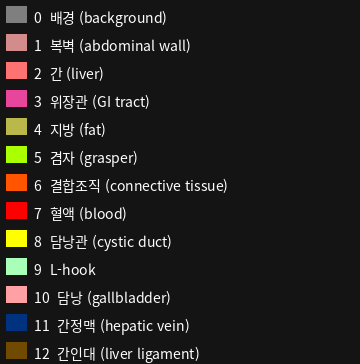


강의용 세 장. 왼쪽 입력, 오른쪽 정답


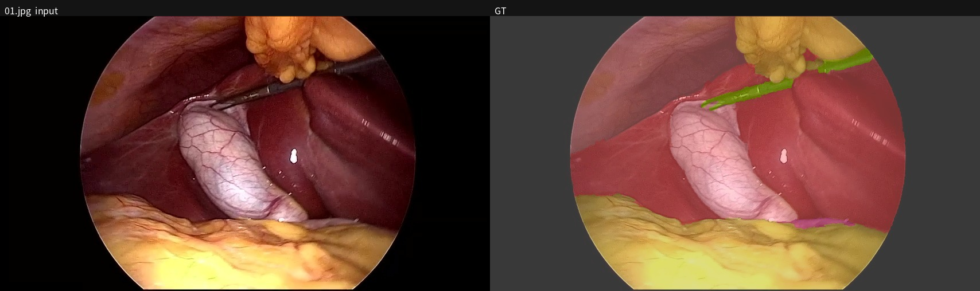

01.jpg 854x480
  복벽 (abdominal wall)    39773 px  (9.7%)
  간 (liver)    95019 px  (23.2%)
  위장관 (GI tract)     1312 px  (0.3%)
  지방 (fat)    78221 px  (19.1%)
  겸자 (grasper)     4770 px  (1.2%)
  담낭 (gallbladder)    25684 px  (6.3%)



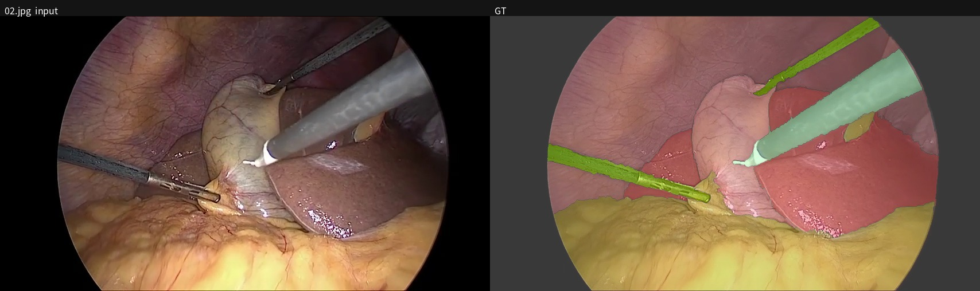

02.jpg 854x480
  복벽 (abdominal wall)    98845 px  (24.1%)
  간 (liver)    54179 px  (13.2%)
  지방 (fat)    86669 px  (21.1%)
  겸자 (grasper)    10763 px  (2.6%)
  L-hook    18652 px  (4.6%)
  담낭 (gallbladder)    23884 px  (5.8%)



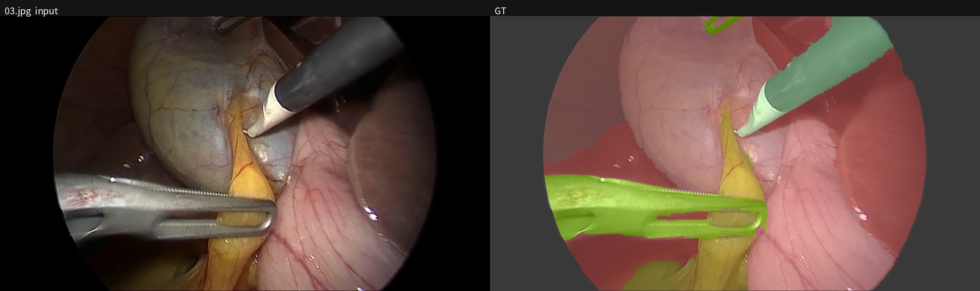

03.jpg 854x480
  복벽 (abdominal wall)    24700 px  (6.0%)
  간 (liver)    81151 px  (19.8%)
  지방 (fat)    22957 px  (5.6%)
  겸자 (grasper)    29655 px  (7.2%)
  L-hook    20926 px  (5.1%)
  담낭 (gallbladder)   110649 px  (27.0%)



In [ ]:
import numpy as np                                   # 숫자 배열(행렬) 계산 라이브러리입니다.
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont          # ImageDraw : 이미지 위에 글씨·도형을 그립니다.

# ── (1) 상수 정의 ──────────────────────────────────
NUM_CLASSES = 13           # 배경(0번) 포함 클래스 개수입니다. 마스크 값은 0 ~ 12 입니다.

# 클래스 번호 순서대로 한글 이름입니다. (리스트의 위치 = 클래스 번호)
CLASS_KO = [
    "배경",
    "복벽",
    "간",
    "위장관",
    "지방",
    "겸자",
    "결합조직",
    "혈액",
    "담낭관",
    "L-hook",
    "담낭",
    "간정맥",
    "간인대",
]
# 같은 순서의 영어 이름입니다.
CLASS_EN = [
    "background",
    "abdominal wall",
    "liver",
    "GI tract",
    "fat",
    "grasper",
    "connective tissue",
    "blood",
    "cystic duct",
    "L-hook",
    "gallbladder",
    "hepatic vein",
    "liver ligament",
]
# 화면에 표시할 이름입니다. 한글과 영어가 같으면(예: L-hook) 하나만, 다르면 "한글 (English)" 형태로 만듭니다.
# zip(a, b) : 두 리스트를 같은 위치끼리 짝지어 한 쌍씩 꺼냅니다.
CLASS_LABEL = [
    ko if ko.lower() == en.lower() else f"{ko} ({en})"
    for ko, en in zip(CLASS_KO, CLASS_EN)
]
# 클래스별 색 (R, G, B) 입니다. 13행 × 3열 배열이며, "행 번호 = 클래스 번호"입니다.
# 예: COLORS[2] 는 간(liver)의 색 [255, 114, 114] 입니다.  dtype=uint8 : 0~255 정수(이미지 표준 형식)
COLORS = np.array(
    [
        [127, 127, 127],
        [210, 140, 140],
        [255, 114, 114],
        [231, 70, 156],
        [186, 183, 75],
        [170, 255, 0],
        [255, 85, 0],
        [255, 0, 0],
        [255, 255, 0],
        [169, 255, 184],
        [255, 160, 165],
        [0, 50, 128],
        [111, 74, 0],
    ],
    dtype=np.uint8,
)
# ImageNet 데이터 전체의 채널별(R, G, B) 평균과 표준편차입니다.
# 인코더(ResNet-50)가 ImageNet으로 사전학습되었기 때문에, 입력도 같은 기준으로 정규화해 줍니다.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


# ── (2) 도구 함수 ──────────────────────────────────
def overlay(img, mask, alpha=0.5):
    # mask(높이×너비, 값=클래스 번호)를 COLORS 표에서 찾아 색 그림(높이×너비×3)으로 바꿉니다.
    # COLORS[mask] 는 "배열 인덱싱"으로, 마스크의 모든 픽셀 값을 한꺼번에 색으로 치환합니다.
    # np.clip : 혹시 범위를 벗어난 값이 있어도 0 ~ 12 안으로 잘라서 오류를 막습니다.
    color = Image.fromarray(COLORS[np.clip(mask, 0, NUM_CLASSES - 1)], "RGB")
    # 크기가 다르면 맞춥니다. 클래스 색이 번지면 안 되므로 NEAREST(가장 가까운 픽셀 복사)를 씁니다.
    if color.size != img.size:
        color = color.resize(img.size, Image.NEAREST)
    # 원본과 색 그림을 alpha 비율로 섞습니다. (alpha=0.5 → 반반)
    return Image.blend(img.convert("RGB"), color, alpha)


def hangul_font(size):
    # 2번 섹션의 hangul_font 와 이름이 같습니다. 파이썬에서는 나중에 정의한 함수가 앞의 것을 덮어씁니다.
    # 이 버전은 메시지를 출력하지 않고, 크기(size)를 반드시 받는 더 간단한 형태입니다.
    for path, index in (
        ("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc", 1),
        ("/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc", 1),
        ("/usr/share/fonts/truetype/nanum/NanumGothic.ttf", None),
        ("/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf", None),
    ):
        if not Path(path).exists():
            continue
        try:
            kw = {"index": index} if index is not None else {}
            return ImageFont.truetype(path, size, **kw)
        except OSError:
            continue
    return None


def font(size):
    # 한글 폰트를 우선 찾고, 없으면 영문 폰트, 그것도 없으면 PIL 기본 폰트를 돌려줍니다.
    # (어떤 환경에서도 오류 없이 글씨를 그리기 위한 '안전망'입니다.)
    found = hangul_font(size)
    if found is not None:
        return found
    for path in (
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf",
    ):
        try:
            return ImageFont.truetype(path, size)
        except OSError:
            continue
    return ImageFont.load_default()


def caption(img, text):
    # 그림 위에 어두운 제목 줄(높이 28px)을 붙이고 글씨를 씁니다.
    bar_h = 28
    # 원본보다 28px 더 높은 어두운 회색(20,20,20) 새 도화지를 만듭니다.
    canvas = Image.new("RGB", (img.width, img.height + bar_h), (20, 20, 20))
    # 원본을 제목 줄 아래(y = bar_h)에 붙여 넣습니다.
    canvas.paste(img.convert("RGB"), (0, bar_h))
    # 제목 줄에 흰색 글씨를 씁니다. (8, 6) 은 글씨 시작 위치 (x, y) 입니다.
    draw = ImageDraw.Draw(canvas)
    draw.text((8, 6), text, fill=(255, 255, 255), font=font(16))
    return canvas


def side_by_side(left, right):
    # 같은 크기의 두 그림을 가로로 이어 붙입니다. (가로 폭은 2배가 됩니다.)
    w, h = left.size
    canvas = Image.new("RGB", (w * 2, h))
    canvas.paste(left, (0, 0))      # 왼쪽 절반
    canvas.paste(right, (w, 0))     # 오른쪽 절반
    return canvas


# ── (3) 실행: 범례 + 예제 세 장 보기 ─────────────────────
print("클래스 색")
legend = ROOT / "examples" / "legend.png"      # 미리 만들어 둔 색 범례 그림입니다.
if legend.exists():
    show_img(Image.open(legend), width=360)
else:
    print("범례가 없다:", legend)

print()
print("강의용 세 장. 왼쪽 입력, 오른쪽 정답")
# glob("[0-9][0-9].jpg") : 이름이 숫자 두 자리인 jpg(01.jpg, 02.jpg …)만 찾습니다. sorted : 이름순 정렬
# (01_gt.jpg 처럼 이름이 더 긴 파일은 이 패턴에 걸리지 않습니다.)
for path in sorted((ROOT / "examples").glob("[0-9][0-9].jpg")):
    img = Image.open(path).convert("RGB")
    # 같은 번호의 정답 마스크(01_mask.png)입니다. path.stem 은 확장자를 뺀 파일 이름("01")입니다.
    mask_path = path.parent / f"{path.stem}_mask.png"
    mask = np.array(Image.open(mask_path)) if mask_path.exists() else None
    # 정답 그림을 정하는 우선순위: ① 미리 칠해 둔 _gt.jpg → ② 마스크로 직접 overlay → ③ 원본 복사
    gt_path = path.parent / f"{path.stem}_gt.jpg"
    if gt_path.exists():
        gt_panel = Image.open(gt_path).convert("RGB")
        if gt_panel.size != img.size:
            gt_panel = gt_panel.resize(img.size, Image.BILINEAR)
    elif mask is not None:
        gt_panel = overlay(img, mask)
    else:
        gt_panel = img.copy()
    # 제목 줄을 붙인 입력 | 정답을 나란히 이어서 보여 줍니다.
    show_img(
        side_by_side(caption(img, f"{path.name}  input"), caption(gt_panel, "GT")),
        width=980,
    )
    if mask is None:
        print()
        continue
    # 클래스별 픽셀 수와 비율을 출력합니다.  (GT = Ground Truth, 정답)
    h, w = mask.shape                       # 마스크의 (세로, 가로)
    print(path.name, f"{w}x{h}")
    for c in range(1, NUM_CLASSES):         # 0번(배경)은 제외하고 1 ~ 12번만 봅니다.
        px = int((mask == c).sum())         # (mask == c) : c번 픽셀만 True → sum() : 개수
        if px == 0:                         # 이 장면에 없는 클래스는 건너뜁니다.
            continue
        # :7d → 7칸 폭의 정수,  :.1% → 비율을 퍼센트로 소수 첫째 자리까지
        print(f"  {CLASS_LABEL[c]}  {px:7d} px  ({px / (w * h):.1%})")
    print()

### 👀 출력 읽는 법

- **색칠된 오른쪽 그림(GT)** 은 사람이 픽셀 단위로 직접 달아 둔 정답입니다. 모델이 **따라 그려야 할 목표**입니다.
- **클래스별 픽셀 수와 비율**을 봅니다. 간·복벽 같은 큰 장기는 화면의 상당 부분을 차지하는 반면, 담낭관·간정맥 같은 작은 구조는 **1%도 안 되는 경우**가 많습니다. 장면마다 어떤 클래스가 있고 없는지도 함께 확인해 보세요.
- 이런 **클래스 불균형(class imbalance)** 은 학습에 큰 영향을 줍니다. 모델이 넓은 장기만 잘 맞춰도 전체 픽셀 정확도는 높게 나오기 때문에, **작은 장기를 무시하기 쉽습니다.** 6번에서 *클래스 가중치*와 *Dice 손실*을 쓰는 이유가 바로 이것입니다.

> 💡 **직접 확인해 보기:** 이 셀을 실행하고 나면 마지막 예제의 마스크가 변수 `mask`에 남아 있습니다. (정답 마스크가 있는 경우) 새 셀에서 `np.unique(mask)` 를 실행하면 **그 장면에 어떤 클래스 번호가 들어 있는지** 바로 볼 수 있습니다.

방금 본 장면은 object detection으로 풀기 어렵습니다. object detection은 객체마다 직사각형 박스 하나를 줍니다. 여기서는 그 박스만으로는 부족합니다.

1. **한 박스 안에 여러 장기가 들어갑니다.** 간(liver)을 감싸면 담낭(gallbladder)과 지방(fat)이 같이 들어갑니다.
2. **작은 구조는 박스가 거의 의미 없습니다.** 담낭관(cystic duct)·간정맥(hepatic vein)은 화면의 1%도 안 되는 경우가 많습니다.

그래서 픽셀마다 클래스를 칠하는 segmentation을 씁니다.

## 5. 신경망 모델

`torchvision`에는 DeepLabV3는 있지만 DeepLabV3+는 없습니다. 아래는 ResNet-50 인코더에 ASPP와 디코더를 붙인 실습용 코드입니다. CholecSeg8K 원 논문도 이 구조를 베이스라인으로 사용했습니다.

U-Net은 매 해상도에서 skip을 붙입니다. DeepLabV3+는 가장 깊은 특징만 ASPP로 봅니다. 1×1 합성곱, 팽창률 6·12·18의 3×3 합성곱, 전역 평균의 다섯 갈래입니다. (그림에서는 1×1 갈래를 `1`로 표기해서 "1, 6, 12, 18"로 적혀 있습니다.) 가장자리 정보용으로는 layer1만 한 번 붙입니다.

`show_deeplab_stack`이 그 경로를 그림으로 그립니다.

### 🧭 DeepLabV3+ 한눈에 보기

입력 이미지가 `288 × 512`(높이 × 너비)일 때 텐서 모양이 어떻게 변하는지 따라가 봅시다. 표기는 **(채널 수, 높이, 너비)** 입니다.

```
입력 이미지                                          (  3, 288, 512)
   │
 stem  (7×7 합성곱 + 풀링)                           ( 64,  72, 128)   ← 1/4 크기
   │
 layer1 ──────────────────────────────┐ (낮은 수준 특징: 경계·질감)
   │                                  │               (256,  72, 128)   ← 1/4
 layer2                               │               (512,  36,  64)   ← 1/8
 layer3                               │               (1024, 18,  32)   ← 1/16
 layer4 (stride 대신 dilation)         │               (2048, 18,  32)   ← 1/16 (더 줄이지 않습니다)
   │                                  │
 ASPP (다섯 가지 시야로 보고 합침)        │               ( 256,  18,  32)
   │                                  │
 4배 확대(upsample)                    │               ( 256,  72, 128)
   ▼                                  ▼
 concat ◀───── layer1을 1×1 합성곱으로 48채널로 줄인 것   ( 304,  72, 128)   (256 + 48)
   │
 decoder (3×3 합성곱 2번)                              ( 256,  72, 128)
   │
 head (1×1 합성곱, 클래스 수만큼 채널)                    (  13,  72, 128)
   │
 4배 확대(upsample)                                    (  13, 288, 512)   ← 입력과 같은 크기
```

마지막 `13`개 채널은 **픽셀마다 13개 클래스의 점수(로짓)** 입니다. 그중 점수가 가장 큰 클래스를 고르면(`argmax`) 마스크가 됩니다.

### 💡 핵심 아이디어 다섯 가지

**① 인코더–디코더: 왜 줄였다가 다시 키우나요?**
이미지를 줄이면(풀링·stride) 넓은 영역을 한 번에 보게 되어 *"여기는 간이다"* 같은 **의미**를 파악하기 쉽고, 계산량도 줄어듭니다. 하지만 **위치 정밀도**는 잃게 됩니다. 그래서 디코더에서 다시 키우면서 픽셀 단위로 복원합니다.

**② Output stride 16: 어디까지 줄이나요?**
ResNet-50은 원래 입력을 1/32까지 줄입니다. 세그멘테이션에는 너무 거칠어서, 마지막 단계(`layer4`)의 **stride를 1로 바꾸고 대신 dilation을 씁니다.** 그러면 1/16 크기를 유지하면서도 시야는 넓게 유지됩니다.

**③ 팽창 합성곱(dilated convolution): 건너뛰며 보기**
같은 3×3 커널이지만 **커널의 칸과 칸 사이 간격을 `d`로 벌려서** 봅니다. **파라미터 수는 그대로**인데 보는 범위만 넓어집니다.

```
d = 1 (보통 합성곱)       d = 2                    d = 6, 12, 18 …
 ■ ■ ■                    ■ · ■ · ■                칸 사이 간격을 훨씬 더 넓게 벌립니다
 ■ ■ ■                    · · · · ·
 ■ ■ ■                    ■ · ■ · ■
 (3칸 폭)                  · · · · ·
                          ■ · ■ · ■  (5칸 폭)
```

3×3 커널이 실제로 보는 폭은 `2d + 1` 칸입니다.

| 팽창률 d | 1 | 6 | 12 | 18 |
|---|---|---|---|---|
| 보는 폭 | 3 | 13 | 25 | 37 |

**④ ASPP: 한 지도를 다섯 가지 시야로 봅니다**
같은 특징 지도에 **① 1×1(한 점), ② d=6, ③ d=12, ④ d=18, ⑤ 전체 평균(이미지 전체 요약)** 을 각각 적용합니다. 결과 5개(각 256채널 = 1280채널)를 이어 붙인 뒤, 1×1 합성곱으로 256채널로 줄이고 Dropout(10%)을 적용합니다. 작은 도구부터 큰 장기까지 **크기가 다른 물체를 한꺼번에** 다루기 위한 장치입니다.

**⑤ 디코더 + layer1 스킵: 뭉개진 경계를 선명하게**
ASPP 출력은 1/16이라 경계가 뭉툭합니다. 이를 4배 키운 뒤, **1/4 크기에서 아직 선명한 `layer1` 정보**를 48채널로 줄여 붙이고(concat) 합성곱으로 다듬습니다. 마지막에 클래스 수만큼 채널을 만들고 입력 크기로 다시 키웁니다.

> 💡 **전이학습(transfer learning):** 인코더(ResNet-50)는 ImageNet으로 미리 학습된 가중치로 시작합니다(`pretrained=True`가 기본값). 이미 "경계, 질감, 모양" 같은 기초 시각 능력을 갖고 있어서 **적은 데이터로도 빨리 배웁니다.** ASPP·디코더·헤드는 무작위 값에서 시작합니다. 7·8번처럼 학습이 끝난 가중치 파일을 불러올 때는 ImageNet 가중치를 받을 필요가 없으므로 `pretrained=False`로 모델을 만듭니다.

### 🧱 기본 블록 `ConvBNReLU` 의 세 부품

| 부품 | 하는 일 |
|---|---|
| `Conv2d` | 필터를 이미지 위에서 움직이며 특징을 뽑습니다. |
| `BatchNorm2d` | 채널별 값의 분포를 정돈해서 학습을 안정시킵니다. |
| `ReLU` | 음수는 0으로, 양수는 그대로 둡니다. (비선형성을 줍니다.) |

### 🔎 코드 구성

| 클래스 / 함수 | 역할 |
|---|---|
| `ConvBNReLU` | 합성곱 → 배치정규화 → ReLU를 묶은 **기본 블록** |
| `ASPP` | 위 ④ 모듈 |
| `DeepLabV3Plus` | 인코더 + ASPP + 디코더 + 헤드를 조립한 **전체 모델** |
| `show_deeplab_stack` | 더미 입력을 흘려서 위 구조도와 같은 그림을 **그려 주는 도구**입니다. (이해용이며 학습과 무관합니다.) |

> 💡 **`nn.Module` 읽는 법:** 파이토치 모델은 `__init__`에서 **부품을 준비**하고, `forward`에서 **부품을 어떤 순서로 연결할지** 적습니다. `model(x)` 처럼 모델을 함수처럼 부르면 `forward(x)`가 실행됩니다.

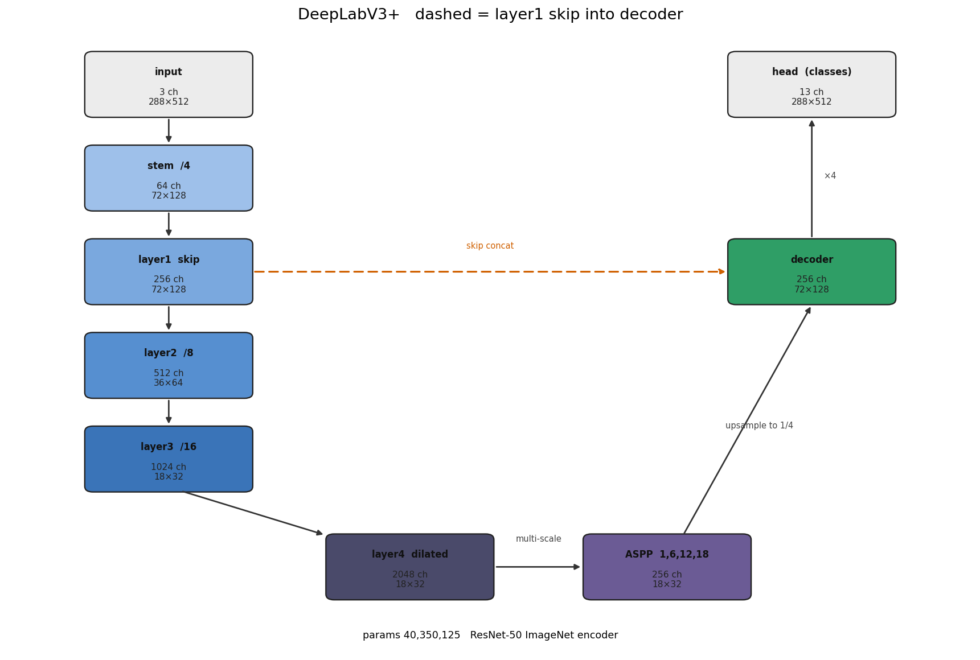

In [ ]:
import torch
from torch import nn                         # 신경망 레이어(Conv2d, BatchNorm2d …)가 들어 있는 모듈입니다.
from torch.nn import functional as F         # 함수 형태의 연산(interpolate, cross_entropy …)입니다.
from torchvision.models import ResNet50_Weights, resnet50   # ResNet-50 구조와 사전학습 가중치입니다.


class ConvBNReLU(nn.Module):
    # (기본 블록) 합성곱 → 배치정규화 → ReLU 를 한 묶음으로 만듭니다.

    def __init__(self, in_ch, out_ch, k=3, d=1):
        # in_ch : 입력 채널 수, out_ch : 출력 채널 수, k : 커널 크기, d : 팽창률(dilation)
        super().__init__()
        # 패딩을 정하는 규칙입니다: 1×1 커널은 0, 3×3 커널은 d 입니다.
        # 3×3 커널은 "팽창률 d만큼 패딩"해야 출력 크기가 입력과 같게 유지됩니다.
        p = 0 if k == 1 else d
        self.net = nn.Sequential(
            # 합성곱입니다. bias=False : 바로 뒤의 BatchNorm이 편향 역할을 대신하므로 필요 없습니다.
            nn.Conv2d(in_ch, out_ch, k, padding=p, dilation=d, bias=False),
            # 배치정규화: 채널별로 값의 분포를 정돈해서 학습을 안정시킵니다.
            nn.BatchNorm2d(out_ch),
            # ReLU: 음수는 0으로, 양수는 그대로 둡니다. (비선형성을 줍니다.) inplace=True : 메모리 절약
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class ASPP(nn.Module):
    """같은 지도를 1x1, 팽창 6/12/18, 전역 평균으로 다섯 갈래에서 본다."""

    def __init__(self, in_ch=2048, out_ch=256, rates=(6, 12, 18)):
        super().__init__()
        # 갈래 4개: ① 1×1 합성곱, ② ~ ④ 팽창률 6/12/18 인 3×3 합성곱입니다.
        # nn.ModuleList : 모듈을 리스트로 담되, 파라미터가 모델에 정상 등록되도록 해 줍니다.
        # *[...] : 리스트 안의 원소를 풀어서 나열합니다.
        self.branches = nn.ModuleList(
            [
                ConvBNReLU(in_ch, out_ch, k=1),
                *[ConvBNReLU(in_ch, out_ch, k=3, d=r) for r in rates],
            ]
        )
        # 갈래 ⑤: 전체 평균 풀링입니다. 가로세로를 1×1로 압축하므로 "이미지 전체를 한 줄로 요약"하는 셈입니다.
        # 그 요약을 1×1 합성곱으로 out_ch 채널로 바꿉니다.
        self.pool = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            ConvBNReLU(in_ch, out_ch, k=1),
        )
        # 다섯 갈래를 이어 붙이면 채널이 out_ch × 5 = 1280 이 됩니다. 이를 1×1 합성곱으로 256채널로 줄이고,
        # 과적합을 막기 위해 Dropout(학습 중 10%의 값을 무작위로 0으로 만듭니다)을 적용합니다.
        self.project = nn.Sequential(
            ConvBNReLU(out_ch * 5, out_ch, k=1),
            nn.Dropout(0.1),
        )

    def forward(self, x):
        # x 모양: (배치, 채널, 높이, 너비). 마지막 두 값이 공간 크기입니다.
        h, w = x.shape[-2:]
        # 갈래 ①~④ 를 각각 통과시킵니다. (모두 같은 높이×너비로 나옵니다.)
        parts = [b(x) for b in self.branches]
        # 갈래 ⑤: 1×1로 요약된 값을 원래 크기(h, w)로 '펼쳐서' 다른 갈래와 모양을 맞춥니다.
        pooled = F.interpolate(self.pool(x), size=(h, w), mode="bilinear", align_corners=False)
        # 채널 방향(dim=1)으로 이어 붙인 뒤 project 로 256채널로 줄입니다.
        return self.project(torch.cat(parts + [pooled], dim=1))


class DeepLabV3Plus(nn.Module):
    """output stride 16. layer4만 dilation, 저수준 skip은 layer1(1/4)이다."""

    def __init__(self, num_classes=13, pretrained=True):
        super().__init__()
        # pretrained=True 이면 ImageNet으로 학습된 가중치를 불러오고, False 이면 무작위 초기화 상태로 만듭니다.
        # (이미 학습한 가중치 파일을 불러올 때는 ImageNet 가중치를 받을 필요가 없어 False 로 씁니다.)
        weights = ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
        # replace_stride_with_dilation=[layer2, layer3, layer4] 에 대해 stride를 dilation으로 바꿀지 여부입니다.
        # layer4만 True → 전체 축소 비율이 1/32 가 아니라 1/16 (output stride 16) 이 됩니다.
        backbone = resnet50(weights=weights, replace_stride_with_dilation=[False, False, True])
        # 분류용 마지막 층(fc)은 쓰지 않고, ResNet의 앞부분(특징 추출기)만 떼어 와서 사용합니다.
        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)  # 1/4
        self.layer1 = backbone.layer1      # 1/4,  256채널  ← 디코더로 가는 skip 에 사용합니다.
        self.layer2 = backbone.layer2      # 1/8,  512채널
        self.layer3 = backbone.layer3      # 1/16, 1024채널
        self.layer4 = backbone.layer4      # 1/16, 2048채널 (dilation 적용)
        self.aspp = ASPP(2048, 256)        # 2048채널 → 256채널
        # skip 으로 오는 layer1(256채널)을 48채널로 줄입니다. 채널이 너무 많으면 ASPP의 풍부한 정보(256채널)를 압도하기 때문입니다.
        self.low = ConvBNReLU(256, 48, k=1)
        # 디코더: concat(256 + 48 = 304채널) → 3×3 합성곱 두 번으로 다듬습니다.
        self.decoder = nn.Sequential(
            ConvBNReLU(256 + 48, 256, k=3),
            ConvBNReLU(256, 256, k=3),
        )
        # 분류 헤드: 1×1 합성곱으로 픽셀마다 num_classes(13)개의 점수(로짓)를 냅니다.
        self.head = nn.Conv2d(256, num_classes, 1)

    def forward(self, x):
        # 마지막에 입력과 같은 크기로 되돌리기 위해 입력의 높이·너비를 기억해 둡니다.
        h, w = x.shape[-2:]
        # ── 인코더 ──
        x = self.stem(x)          # 1/4
        low = self.layer1(x)      # 1/4  (skip 용으로 따로 보관합니다.)
        x = self.layer2(low)      # 1/8
        x = self.layer3(x)        # 1/16
        x = self.layer4(x)        # 1/16 (dilation)
        # ── ASPP: 다섯 가지 시야로 보고 합치기 ──
        x = self.aspp(x)
        # ── 디코더 ──
        # ASPP 출력(1/16)을 skip(low, 1/4)과 같은 크기로 키웁니다.
        x = F.interpolate(x, size=low.shape[-2:], mode="bilinear", align_corners=False)
        # 키운 x 와 (48채널로 줄인) low 를 채널 방향으로 이어 붙이고, 디코더를 통과시킵니다.
        x = self.decoder(torch.cat([x, self.low(low)], dim=1))
        # 클래스별 점수 지도입니다. (배치, 13, 1/4 높이, 1/4 너비)
        x = self.head(x)
        # 입력과 같은 크기로 4배 확대해서 반환합니다. 반환값 모양: (배치, 13, h, w)
        return F.interpolate(x, size=(h, w), mode="bilinear", align_corners=False)


def show_deeplab_stack(model, h=288, w=512):
    """더미 한 장을 통과시킨 뒤, ASPP와 layer1 skip을 그림으로 그린다."""
    # ※ 이 함수는 모델의 일부가 아니라 '구조도를 그리는 도구'입니다. matplotlib 문법은 몰라도 괜찮습니다.
    #   핵심은 "각 단계마다 (채널 수, 높이×너비)가 어떻게 바뀌는지"를 눈으로 확인하는 것입니다.
    from io import BytesIO

    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch
    from PIL import Image

    # ── (1) 더미 입력을 단계별로 통과시키며 중간 결과를 변수에 저장합니다. ──
    model.eval()                     # 평가 모드입니다. (Dropout 끄기, BatchNorm 고정)
    x = torch.zeros(1, 3, h, w)      # 0으로 채운 가짜 이미지 1장입니다. 모양만 보면 되므로 값은 상관없습니다.
    with torch.no_grad():            # 기울기 계산을 끕니다. (메모리·시간 절약)
        # forward() 안에서 일어나는 일을 한 단계씩 풀어서 실행합니다.
        stem = model.stem(x)
        low = model.layer1(stem)
        l2 = model.layer2(low)
        l3 = model.layer3(l2)
        l4 = model.layer4(l3)
        aspp = model.aspp(l4)
        aspp_up = F.interpolate(aspp, size=low.shape[-2:], mode="bilinear", align_corners=False)
        dec = model.decoder(torch.cat([aspp_up, model.low(low)], dim=1))
        out = F.interpolate(model.head(dec), size=(h, w), mode="bilinear", align_corners=False)

    def label(t):
        # 텐서 t 의 모양을 "채널 수 ch \n 높이×너비" 문자열로 만듭니다. (상자 안에 적을 글씨)
        _, c, hh, ww = t.shape
        return f"{c} ch\n{hh}×{ww}"

    # ── (2) 그림 바탕 만들기 ──
    fig, ax = plt.subplots(figsize=(12.4, 8.4))
    ax.set_xlim(0, 12)               # 좌표 범위를 지정합니다. (x : 0~12, y : 0.2~11.2)
    ax.set_ylim(0.2, 11.2)
    ax.axis("off")                   # 눈금·테두리를 숨깁니다.
    ax.set_title("DeepLabV3+   dashed = layer1 skip into decoder", fontsize=14, pad=8)
    boxes = {}                       # 각 상자의 위치를 저장해 두었다가 화살표를 그릴 때 씁니다.

    def box(key, cx, cy, title, tensor, color):
        # 중심 (cx, cy) 에 둥근 사각형을 그리고, 위쪽에 제목, 아래쪽에 텐서 모양을 적습니다.
        bw, bh = 2.05, 1.12
        patch = FancyBboxPatch(
            (cx - bw / 2, cy - bh / 2),
            bw,
            bh,
            boxstyle="round,pad=0.02,rounding_size=0.1",
            facecolor=color,
            edgecolor="#222",
            linewidth=1.2,
        )
        ax.add_patch(patch)
        ax.text(cx, cy + 0.22, title, ha="center", va="center", fontsize=8.5, fontweight="bold", color="#111")
        ax.text(cx, cy - 0.22, label(tensor), ha="center", va="center", fontsize=8, color="#222")
        boxes[key] = (cx, cy, bw, bh)

    def down(src, dst):
        # 상자 src 의 아래쪽에서 상자 dst 의 위쪽으로 향하는 화살표입니다.
        x1, y1, _, h1 = boxes[src]
        x2, y2, _, h2 = boxes[dst]
        ax.annotate(
            "",
            xy=(x2, y2 + h2 / 2 + 0.02),
            xytext=(x1, y1 - h1 / 2 - 0.02),
            arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.4, mutation_scale=10),
        )

    # ── (3) 상자 배치: 인코더(왼쪽, 파란 계열) → layer4 → ASPP(아래) → 디코더(오른쪽, 초록) → 출력 ──
    box("in", 2.0, 10.2, "input", x, "#ececec")
    box("stem", 2.0, 8.55, "stem  /4", stem, "#9ec0ea")
    box("low", 2.0, 6.9, "layer1  skip", low, "#7aa8de")
    box("l2", 2.0, 5.25, "layer2  /8", l2, "#568fd0")
    box("l3", 2.0, 3.6, "layer3  /16", l3, "#3a74b8")
    box("l4", 5.0, 1.7, "layer4  dilated", l4, "#4a4a6a")
    box("aspp", 8.2, 1.7, "ASPP  1,6,12,18", aspp, "#6b5b95")
    box("dec", 10.0, 6.9, "decoder", dec, "#2f9e66")
    box("head", 10.0, 10.2, "head  (classes)", out, "#ececec")
    # ── (4) 화살표: 데이터가 흐르는 방향 ──
    # 인코더 내부 (위 → 아래)
    down("in", "stem")
    down("stem", "low")
    down("low", "l2")
    down("l2", "l3")
    # layer3 → layer4
    x1, y1, _, h1 = boxes["l3"]
    x2, y2, _, h2 = boxes["l4"]
    ax.annotate(
        "",
        xy=(x2 - 1.05, y2 + h2 / 2),
        xytext=(x1 + 0.15, y1 - h1 / 2),
        arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.4, mutation_scale=10),
    )
    # layer4 → ASPP
    x3, y3, _, h3 = boxes["aspp"]
    ax.annotate(
        "",
        xy=(x3 - 1.05, y3),
        xytext=(x2 + 1.05, y2),
        arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.4, mutation_scale=10),
    )
    ax.text(6.6, 2.15, "multi-scale", fontsize=7.5, color="#444", ha="center")
    # ASPP → 디코더 (1/4 크기로 확대해서 전달합니다.)
    x4, y4, w4, h4 = boxes["aspp"]
    x5, y5, w5, h5 = boxes["dec"]
    ax.annotate(
        "",
        xy=(x5, y5 - h5 / 2 - 0.02),
        xytext=(x4 + 0.2, y4 + h4 / 2),
        arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.4, mutation_scale=10),
    )
    ax.text(9.35, 4.15, "upsample to 1/4", fontsize=7.5, color="#444", ha="center")
    # layer1 → 디코더: 주황색 점선 = 스킵 연결(skip concat). 이 그림에서 가장 중요한 화살표입니다.
    x6, y6, w6, _ = boxes["low"]
    ax.annotate(
        "",
        xy=(x5 - w5 / 2 - 0.02, y5),
        xytext=(x6 + w6 / 2 + 0.02, y6),
        arrowprops=dict(arrowstyle="-|>", color="#d06000", lw=1.6, ls=(0, (5, 3)), mutation_scale=10),
    )
    ax.text((x6 + x5) / 2, y6 + 0.42, "skip concat", ha="center", fontsize=7.5, color="#d06000")
    # 디코더 → 출력 헤드 (×4 확대)
    x7, y7, _, h7 = boxes["dec"]
    x8, y8, _, h8 = boxes["head"]
    ax.annotate(
        "",
        xy=(x8, y8 - h8 / 2 - 0.02),
        xytext=(x7, y7 + h7 / 2 + 0.02),
        arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.4, mutation_scale=10),
    )
    ax.text(x7 + 0.15, (y7 + y8) / 2, "×4", fontsize=7.5, color="#444", ha="left")
    # 모델의 전체 파라미터(학습되는 숫자) 개수를 그림 아래에 적습니다. (약 4천만 개)
    n = sum(p.numel() for p in model.parameters())
    ax.text(6.0, 0.45, f"params {n:,}   ResNet-50 ImageNet encoder", ha="center", fontsize=9)
    # ── (5) 그림을 메모리에 PNG로 저장했다가 노트북에 표시합니다. ──
    fig.tight_layout()
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=140, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    buf.seek(0)
    show_img(Image.open(buf), width=980)


# 모델을 만들어(pretrained=False : 구조만 필요하므로 가중치를 받지 않습니다) CPU에 올린 뒤 구조도를 그립니다.
show_deeplab_stack(DeepLabV3Plus(num_classes=NUM_CLASSES, pretrained=False).to("cpu"))

### 👀 그림 읽는 법

- **파란 상자(왼쪽 위 → 아래)** 는 인코더입니다. 아래로 갈수록 **채널은 늘고(64 → 2048) 크기는 줄어듭니다.** 단, `layer4`는 `/16` 그대로 유지됩니다.
- **보라색 상자(ASPP)** 는 `layer4` 출력을 다섯 가지 시야로 본 결과입니다. 채널이 2048 → 256으로 줄어듭니다.
- **초록 상자(decoder)** 에서 ASPP 결과(4배 확대)와 **주황색 점선(layer1 skip)** 이 합쳐집니다.
- 맨 위 **head** 의 채널이 `13` 입니다. 입력과 **같은 크기(288×512)** 로 되돌아온 13장의 점수 지도입니다.
- 그림 아래 `params …` 는 학습 대상 숫자(파라미터)의 총 개수이며, 약 **4천만 개**입니다.

> 💡 **이 모델은 U-Net과 어떻게 다른가요?** U-Net은 모든 해상도에서 skip을 붙이지만, DeepLabV3+는 **가장 깊은 특징을 ASPP로 풍부하게 본 뒤, 경계용으로 `layer1` skip을 딱 한 번** 붙입니다.

## 6. 학습

Dice는 예측한 칠과 정답 칠이 얼마나 겹치는지를 0에서 1 사이로 나타낸 값입니다. 교집합을 두 배로 한 뒤, 예측 픽셀 수와 정답 픽셀 수의 합으로 나눕니다. 1이면 그 종류의 픽셀이 완전히 같고, 0이면 겹치는 픽셀이 없습니다.

픽셀 정확도로 모델을 고르지 않는 이유는 배경 때문입니다. 화면의 대부분이 배경이면 전부 배경으로 찍어도 정확도는 높게 나옵니다. 교차엔트로피도 픽셀마다 틀렸는지를 보기 때문에, 간(liver)·지방(fat)처럼 넓은 장기가 손실을 지배합니다. 그래서 이 노트북은 두 가지를 함께 사용합니다. 하나는 작은 클래스에 더 큰 가중치를 주는 **클래스 가중치**이고, 다른 하나는 Dice를 종류마다 구한 뒤 배경을 빼고 평균하는 **Dice 손실**입니다. 이렇게 하면 담낭관(cystic duct)처럼 작은 장기도 간과 같은 비중으로 평균에 들어갑니다. 최종 손실은 (클래스 가중치를 곱한) 교차엔트로피와 이 Dice 손실을 더한 값입니다.

에폭마다 검증 세트에서 배경을 뺀 평균 Dice를 계산하고, 가장 높은 가중치를 `best_colab.pt`로 저장합니다. 배경은 화면을 많이 차지하므로 평균에 넣으면 점수가 항상 높아 보입니다. 검증은 가중치를 고르는 용도일 뿐 최종 점수가 아닙니다. 테스트 비디오는 학습과 모델 선택에 쓰지 않습니다.

이 셀은 손실과 체크포인트를 고르는 방법을 보여 주는 12 epoch 학습입니다. T4에서 10분 안팎이 걸립니다. zip의 `runs/best.pt`는 덮어쓰지 않으며, 7번 평가와 8번 시연은 그 파일을 읽습니다. 시연만 하려면 이 셀은 건너뛰어도 됩니다.

### 🗺️ 학습 셀 한눈에 보기

아래 셀은 길지만, 위에서 아래로 **일곱 덩어리**일 뿐입니다. 코드 안의 구간 제목(①~⑦)과 같은 번호입니다.

| 번호 | 덩어리 | 한 줄 설명 |
|---|---|---|
| ① | **하이퍼파라미터** | 에폭 수, 배치 크기, 이미지 크기, 학습률 같은 "설정값"입니다. |
| ② | **`OrganDataset`** | 이미지와 마스크를 한 쌍씩 읽고 → 크기를 줄이고 → (학습일 때) 증강하고 → 텐서로 바꿉니다. `set_seed`도 여기에 있습니다. |
| ③ | **`class_weights`** | 클래스별 픽셀 비율을 세어서 **작은 클래스에 더 큰 가중치**를 줍니다. |
| ④ | **`ce_dice`** | 학습에서 줄이려는 값(**손실**) = 가중 교차엔트로피 + Dice 손실입니다. |
| ⑤ | **`eval_metrics`** | 검증 세트에서 **Dice, IoU** 를 계산합니다. |
| ⑥ | **학습 준비** | 데이터셋·DataLoader·모델·옵티마이저·스케줄러·클래스 가중치를 만듭니다. |
| ⑦ | **학습 루프** | 에폭마다 "예측 → 손실 계산 → 가중치 수정 → 검증 → 최고 기록이면 저장"을 반복합니다. |

### ⚙️ 하이퍼파라미터 (셀 맨 위의 설정값)

| 이름 | 값 | 의미 | 바꾸면? |
|---|---|---|---|
| `EPOCHS` | 12 | 학습 데이터를 도는 횟수입니다. | 늘리면 오래 학습하지만, 과적합 위험도 커집니다. |
| `BATCH` | 4 | 한 번에 처리하는 이미지 수입니다. | GPU 메모리가 부족하면 줄입니다. |
| `WIDTH, HEIGHT` | 512, 288 | 모델에 넣기 전에 줄일 크기입니다. | 키우면 정확도는 오를 수 있지만 느려집니다. 16의 배수를 권합니다. |
| `LR` | 3e-4 | 학습률(가중치를 한 번에 바꾸는 크기)입니다. | 너무 크면 불안정하고, 너무 작으면 학습이 느립니다. |
| `SEED` | 42 | 난수 시드입니다. | 같은 값이면 비슷한 결과를 재현할 수 있습니다. |

---

### 📐 Dice와 IoU를 숫자로 이해하기

예측이 칠한 픽셀이 **100개**, 정답이 칠한 픽셀이 **120개**, 둘이 **겹친 픽셀이 80개**라고 해 봅시다.

$$\text{Dice} = \frac{2 \times \text{겹침}}{\text{예측} + \text{정답}} = \frac{2 \times 80}{100 + 120} = 0.727 \qquad
\text{IoU} = \frac{\text{겹침}}{\text{예측} + \text{정답} - \text{겹침}} = \frac{80}{140} = 0.571$$

- 완벽히 일치하면 **1**, 전혀 겹치지 않으면 **0** 입니다.
- 같은 칠이라도 **IoU는 Dice보다 항상 낮거나 같습니다.** (두 값은 `IoU = Dice / (2 − Dice)` 관계입니다.) 점수를 비교할 때는 **같은 지표끼리** 비교하세요.
- 클래스마다 **따로** 구한 뒤 평균을 냅니다. 그래서 *픽셀이 아주 적은 담낭관*도 *픽셀이 아주 많은 간*과 **같은 비중**으로 평균에 들어갑니다.

> 💡 **손실에 쓰는 Dice와 평가에 쓰는 Dice는 계산 방식이 조금 다릅니다.**
> - **손실(④)** : softmax **확률**을 그대로 써서 계산합니다(soft Dice). 확률은 미분이 가능해서 학습에 쓸 수 있습니다. 한 배치 안에서 클래스별로 구합니다.
> - **평가(⑤)** : `argmax`로 클래스를 확정한 **칠(0 또는 1)** 로 계산합니다. 검증·테스트 세트 **전체의 픽셀 수를 먼저 누적한 뒤** 클래스별로 한 번 계산합니다.

---

### ⚖️ 클래스 가중치: 작은 클래스에 더 큰 목소리를

가중치 공식은 $w_c = \dfrac{1}{\ln(1.02 + f_c)}$ 입니다. $f_c$ 는 클래스 $c$ 가 전체 학습 픽셀에서 차지하는 **비율**입니다. (ENet 논문에서 쓰인 방식입니다.)

| 클래스가 차지하는 비율 $f_c$ | 가중치 $w_c$ (정규화 전) |
|---|---|
| 30 % (넓은 장기) | 약 **3.6** |
| 5 % | 약 14.8 |
| 1 % | 약 33.8 |
| 0.1 % (아주 작은 구조) | 약 **48.1** |

→ 아주 작은 클래스의 틀림이 손실에 **약 13배** 더 크게 반영됩니다. 식 안의 `1.02` 는 $f_c \to 0$ 일 때 가중치가 **무한히 커지는 것을 막는 안전장치**입니다. (최대 약 50.5)

코드가 가중치를 만드는 순서는 다음과 같습니다.

1. 학습 마스크 PNG를 **모두 읽어서** 클래스별 픽셀 수를 셉니다. (줄이기 전의 원본 크기 기준입니다.)
2. 위 공식으로 가중치를 계산합니다.
3. 학습 데이터에 **아예 없는 클래스는 가중치를 0**으로 둡니다.
4. 존재하는 클래스들의 **평균이 1**이 되도록 나눕니다.

> 💡 **4단계(평균 1로 나누기)의 의미:** 클래스 사이의 **비율은 그대로** 두고 값을 다루기 쉬운 크기로 맞추는 정규화입니다. 참고로 파이토치의 가중 교차엔트로피는 평균을 낼 때 **가중치의 합으로 나누기** 때문에, 가중치 전체에 같은 수를 곱하거나 나눠도 **손실 값은 변하지 않습니다.** 결과에 영향을 주는 것은 클래스 사이의 *비율*뿐입니다.

---

### 🧮 손실 함수 = 가중 교차엔트로피 + Dice

| | 교차엔트로피 (CE) | Dice 손실 |
|---|---|---|
| 보는 단위 | **픽셀 하나하나** | **클래스별로 칠한 영역** |
| 약점 | 넓은 장기가 손실을 지배합니다. | 영역 전체의 겹침만 보므로, 단독으로 쓰면 학습이 불안정해지기 쉽다고 알려져 있습니다. |
| 이 코드에서의 보완 | 클래스 가중치를 곱합니다. | 분모·분자에 `+1`(스무딩)을 더해 0으로 나누는 것을 막습니다. |

두 손실을 **더해서** 서로의 약점을 메웁니다. Dice 손실은 `1 − Dice`이므로 겹칠수록 0에 가까워집니다. 또한 **배경(0번)은 평균에서 빼서**, 작은 장기가 배경에 묻히지 않게 합니다.

> 💡 **배치에 어떤 클래스가 없다면?** 정답에 그 클래스가 없고 예측 확률도 거의 0이면 Dice 손실은 0에 가깝습니다. 반대로 정답에 없는데 모델이 그 클래스를 많이 칠하면(오탐) 손실이 1에 가까워져 **벌점**을 받습니다. `+1` 스무딩 덕분에 클래스가 없어도 0으로 나누는 오류가 나지 않습니다.

---

### 🎲 데이터 증강: 학습 이미지에만 적용합니다

| 증강 | 적용 대상 | 이유 |
|---|---|---|
| 50% 확률로 **좌우 반전** | 이미지 **와 마스크 모두 똑같이** | 한쪽만 뒤집으면 칠한 위치가 어긋납니다. |
| **ColorJitter** (밝기·대비 ±20%, 채도 ±15%, 색조 ±0.02) | **이미지에만** | 마스크 값은 클래스 번호이므로 바꾸면 안 됩니다. |

검증·테스트 데이터에는 증강을 적용하지 않습니다. 평가는 **있는 그대로의 데이터**로 해야 공정하기 때문입니다.

### 🔀 학습 모드와 평가 모드

| | `model.train()` | `model.eval()` |
|---|---|---|
| Dropout | 켜집니다. (일부 값을 무작위로 끕니다.) | 꺼집니다. |
| BatchNorm | 현재 배치로 통계를 계산하고 갱신합니다. | 학습 때 모은 통계를 고정해서 씁니다. |
| 언제 쓰나요? | 학습 루프 | 검증·테스트·추론 |

`eval_metrics`는 함수 안에서 `model.eval()`을 호출하고 그 상태로 끝납니다. 그래서 학습 루프는 **에폭이 시작될 때마다 `model.train()`을 다시 호출**합니다. 평가할 때는 `@torch.no_grad()`로 기울기 계산도 꺼서 메모리와 시간을 아낍니다.

### 📦 한 배치의 텐서 모양 (`BATCH=4` 기준)

| 변수 | 모양 | 자료형 | 설명 |
|---|---|---|---|
| `x` | `(4, 3, 288, 512)` | float32 | 정규화된 입력 이미지 |
| `y` | `(4, 288, 512)` | int64 | 정답 마스크 (값 = 클래스 번호) |
| `model(x)` | `(4, 13, 288, 512)` | float32 | 클래스별 점수(로짓) |

### 🔁 학습 루프 5단계 (배치마다 반복)

```
1단계  optimizer.zero_grad()   : 이전 배치에서 계산해 둔 기울기를 지웁니다
2단계  model(x)                : 입력 이미지로 예측합니다 (순전파, forward)
3단계  loss = ce_dice(...)     : 예측과 정답을 비교해 손실을 계산합니다
4단계  loss.backward()         : 손실이 줄어드는 방향(기울기)을 계산합니다 (역전파, backward)
5단계  optimizer.step()        : 기울기대로 가중치를 조금 수정합니다
```

옵티마이저는 **AdamW**(기울기를 보고 가중치를 수정하는 알고리즘인 Adam에 가중치 감쇠를 개선해서 붙인 방식)를 씁니다. 학습률은 `CosineAnnealingLR` 스케줄러가 **코사인 곡선 모양으로 천천히 줄여** 줍니다. 에폭이 끝날 때마다 한 단계씩 줄어서, 처음에는 크게 배우고(3e-4) 마지막 에폭에서는 거의 미세 조정만 합니다(1e-6에 근접).

In [ ]:
import json
import random                                  # 파이썬 기본 난수입니다. (좌우 반전 여부를 정할 때 씁니다.)

import torch
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset                 # 데이터를 배치 단위로 공급하는 도구입니다.
from torchvision.transforms import ColorJitter                   # 밝기·대비 등을 무작위로 바꾸는 증강입니다.
from torchvision.transforms.functional import normalize, to_tensor

# ── ① 하이퍼파라미터 (학습 '설정값') ───────────────────────
EPOCHS = 12                 # 학습 데이터를 처음부터 끝까지 몇 바퀴 돌 것인가
BATCH = 4                   # 한 번에 모델에 넣는 이미지 수입니다. GPU 메모리가 부족하면 줄이세요.
WIDTH, HEIGHT = 512, 288    # 모델에 넣기 전에 줄일 크기입니다. 16의 배수여서 1/16 크기로 줄일 때 나머지 없이 떨어집니다.
LR = 3e-4                   # 학습률 (한 번에 가중치를 얼마나 크게 바꿀지)
SEED = 42                   # 난수 시드입니다. 같은 값을 쓰면 실행할 때마다 비슷한 결과가 나옵니다.


# ── ② 데이터셋: 이미지 한 장과 마스크 한 장을 짝지어 읽습니다 ──────
class OrganDataset(Dataset):
    # PyTorch Dataset 은 세 가지 약속(__init__, __len__, __getitem__)만 지키면 됩니다.
    def __init__(self, img_dir, lab_dir, size, augment=False):
        # 이미지 폴더의 모든 jpg 파일을 이름순으로 모읍니다.
        self.images = sorted(img_dir.glob("*.jpg"))
        if not self.images:
            raise FileNotFoundError(img_dir)       # 이미지가 하나도 없으면 오류를 냅니다.
        self.lab_dir = lab_dir                     # 마스크(png) 폴더
        self.size = size                           # (가로, 세로) = (512, 288)
        self.augment = augment                     # True 이면 학습용 증강을 적용합니다.
        # 색 증강: 밝기·대비 ±20%, 채도 ±15%, 색조 ±0.02 범위에서 무작위로 바꿉니다.
        # 수술실 조명·카메라 상태가 다양한 상황에 대비해 모델을 튼튼하게 만듭니다.
        self.jitter = ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15, hue=0.02)

    def __len__(self):
        # 데이터가 총 몇 개인지 알려 줍니다.
        return len(self.images)

    def __getitem__(self, idx):
        # idx 번째 (이미지, 마스크) 한 쌍을 읽어서 모델에 넣을 수 있는 형태로 돌려줍니다.
        img_p = self.images[idx]
        # 이미지 이름과 같은 이름의 png 가 정답 마스크입니다. (예: 0001.jpg ↔ 0001.png)
        lab_p = self.lab_dir / f"{img_p.stem}.png"
        # 이미지는 부드럽게(BILINEAR) 줄여도 되지만,
        img = Image.open(img_p).convert("RGB").resize(self.size, Image.BILINEAR)
        # 마스크는 반드시 NEAREST 로 줄입니다. 값이 클래스 번호라서 섞으면 존재하지 않는 번호가 생기기 때문입니다.
        # (예: 간(2)과 지방(4) 사이를 부드럽게 섞으면 3, 즉 '위장관'이 되어 버립니다.)
        mask = Image.open(lab_p).resize(self.size, Image.NEAREST)
        if self.augment:
            # 50% 확률로 좌우 반전합니다. 이미지와 마스크에 '반드시 똑같이' 적용해야 위치가 어긋나지 않습니다.
            if random.random() < 0.5:
                img = img.transpose(Image.FLIP_LEFT_RIGHT)
                mask = mask.transpose(Image.FLIP_LEFT_RIGHT)
            # 색 변화는 이미지에만 적용합니다. (마스크 값을 바꾸면 안 됩니다.)
            img = self.jitter(img)
        # to_tensor : PIL 이미지(높이×너비×3, 0~255) → 텐서(3×높이×너비, 0~1)
        # normalize : (값 − 평균) / 표준편차. ImageNet 기준으로 맞춰서 사전학습된 인코더가 잘 반응하게 합니다.
        x = normalize(to_tensor(img), IMAGENET_MEAN, IMAGENET_STD)
        # 마스크를 정수(int64) 텐서로 만듭니다. 손실 함수가 클래스 번호를 정수로 요구하기 때문입니다.
        # clamp : 혹시 0~12 밖의 값이 있어도 범위 안으로 잘라서 오류를 막습니다.
        y = torch.from_numpy(np.array(mask, dtype=np.int64)).clamp(0, NUM_CLASSES - 1)
        return x, y, img_p.name          # (입력 3×H×W, 정답 H×W, 파일 이름)


def set_seed(seed):
    # 난수를 고정해서 실험 결과를 최대한 재현 가능하게 만듭니다.
    # (GPU 연산 특성상 완전히 같은 값이 나온다고 보장하지는 않습니다.)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ── ③ 클래스 가중치: 작은 클래스에 더 큰 가중치 ──────────────
def class_weights(lab_dir):
    # (1) 모든 학습 마스크를 읽어서 클래스별 픽셀 수를 셉니다. (줄이지 않은 원본 크기 기준입니다.)
    counts = np.zeros(NUM_CLASSES, dtype=np.float64)
    for path in lab_dir.glob("*.png"):
        mask = np.array(Image.open(path))
        # np.bincount : 값(0~12)이 각각 몇 번 나왔는지 셉니다. ravel() : 2차원을 1차원으로 폅니다.
        counts += np.bincount(mask.ravel(), minlength=NUM_CLASSES)
    # (2) 클래스별 비율 f_c 입니다. (max(…, 1.0) 는 0으로 나누는 오류를 막습니다.)
    freq = counts / max(counts.sum(), 1.0)
    # (3) 가중치 = 1 / ln(1.02 + 비율). 비율이 작을수록 가중치가 커집니다.
    w = 1.0 / np.log(1.02 + freq)
    # 학습 데이터에 아예 없는 클래스는 가중치를 0으로 둡니다.
    w[counts == 0] = 0.0
    # (4) 존재하는 클래스들의 평균 가중치가 1이 되도록 나눕니다.
    #     클래스 사이의 '비율'은 그대로이고, 값을 다루기 쉬운 크기(평균 1)로 맞추는 정규화입니다.
    #     (교차엔트로피는 가중치 합으로 나누는 '가중 평균'이라서, 전체 배율을 바꿔도 CE 값은 변하지 않습니다.)
    pos = w[counts > 0]
    if pos.size:
        w = w / pos.mean()
    # 파이토치 텐서로 바꿔서 GPU/CPU(DEVICE)에 올립니다.
    return torch.tensor(w, dtype=torch.float32, device=DEVICE)


# ── ④ 손실 함수: 가중 교차엔트로피 + Dice ───────────────────
def ce_dice(logits, target, weight=None):
    # logits : 모델 출력 (배치 B, 클래스 13, 높이 H, 너비 W) / target : 정답 (B, H, W), 값은 클래스 번호
    # (1) 교차엔트로피: 픽셀마다 정답 클래스의 확률이 낮을수록 큰 손실입니다.
    #     weight 로 정답 클래스별 중요도를 곱하고, 평균을 낼 때는 가중치의 합으로 나눕니다. (가중 평균)
    ce = F.cross_entropy(logits, target, weight=weight)
    # (2) Dice 손실 준비
    # softmax : 클래스별 점수를 '합이 1인 확률'로 바꿉니다. (dim=1 : 클래스 방향으로)
    pred = logits.softmax(dim=1)
    # one_hot : 정답 번호를 [0,0,1,0,…] 처럼 13칸 벡터로 바꿉니다. (B,H,W) → (B,H,W,13)
    # permute : 축 순서를 (B,13,H,W) 로 바꿔 pred 와 모양을 맞춥니다.
    oh = F.one_hot(target, NUM_CLASSES).permute(0, 3, 1, 2).float()
    # 클래스별로 (배치·세로·가로 전체를 합쳐서) 겹침과 크기를 구합니다. → 길이 13짜리 벡터
    # 예측은 확정된 0/1 이 아니라 '확률'이므로, 확률 × 정답을 더한 값이 겹침의 역할을 합니다. (soft Dice)
    num = 2 * (pred * oh).sum(dim=(0, 2, 3))                    # 2 × 겹침
    den = pred.sum(dim=(0, 2, 3)) + oh.sum(dim=(0, 2, 3))        # 예측 크기 + 정답 크기
    # 1 − Dice 입니다. 분자·분모에 1을 더하는 것(스무딩)은 0으로 나누는 것을 막고 값을 안정시킵니다.
    dice = 1 - (num + 1.0) / (den + 1.0)
    # dice[1:] : 0번(배경)을 빼고 평균합니다. 최종 손실 = CE + Dice 손실
    return ce + dice[1:].mean()


# ── ⑤ 평가 지표: Dice, IoU ──────────────────────────────
@torch.no_grad()      # 이 함수 안에서는 기울기를 계산하지 않습니다. (평가에는 필요 없고, 메모리·시간이 절약됩니다.)
def eval_metrics(model, loader):
    model.eval()      # 평가 모드: Dropout 을 끄고, BatchNorm 은 학습 때 모은 통계를 사용합니다.
    # 클래스별 누적값을 담을 빈 그릇입니다. (길이 13)
    inter = torch.zeros(NUM_CLASSES)       # 겹친 픽셀 수 (교집합)
    union = torch.zeros(NUM_CLASSES)       # 합친 픽셀 수 (합집합)
    pred_sum = torch.zeros(NUM_CLASSES)    # 예측이 칠한 픽셀 수
    tgt_sum = torch.zeros(NUM_CLASSES)     # 정답이 칠한 픽셀 수
    # 검증 세트를 배치 단위로 돌며 픽셀 수를 '누적'합니다.
    for x, y, _ in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        # 모델 출력(B,13,H,W)에서 가장 점수가 높은 클래스를 고릅니다 → 예측 마스크 (B,H,W)
        pred = model(x).argmax(dim=1)
        for c in range(NUM_CLASSES):
            p = pred == c         # 예측이 c번이라고 한 픽셀 (True/False 지도)
            t = y == c            # 정답이 c번인 픽셀
            inter[c] += (p & t).sum().item()    # 둘 다 c번 → 교집합
            union[c] += (p | t).sum().item()    # 둘 중 하나라도 c번 → 합집합
            pred_sum[c] += p.sum().item()
            tgt_sum[c] += t.sum().item()
    # 누적한 값으로 클래스별 Dice, IoU 를 한 번에 계산합니다. (1e-6 : 0으로 나누기 방지)
    dice = (2 * inter + 1e-6) / (pred_sum + tgt_sum + 1e-6)
    iou = (inter + 1e-6) / (union + 1e-6)
    # 정답에 한 픽셀이라도 있는 클래스만 평균에 넣습니다. (배경 0번은 제외하고 1~12번만 봅니다.)
    # tgt_sum 은 검증 세트 전체에서 누적한 값이므로, '검증 세트 어디에도 없는 클래스'만 빠집니다.
    present = [c for c in range(1, NUM_CLASSES) if tgt_sum[c] > 0]
    return {
        "dice": float(dice[present].mean()) if present else 0.0,
        "iou": float(iou[present].mean()) if present else 0.0,
    }


# ── ⑥ 학습 준비 ────────────────────────────────────────
set_seed(SEED)
size = (WIDTH, HEIGHT)                   # PIL 은 (가로, 세로) 순서입니다.
data = ROOT / "dataset"
runs = ROOT / "runs"
# 학습용은 증강 ON, 검증용은 증강 OFF 입니다. (검증은 '있는 그대로' 평가해야 하므로)
train_ds = OrganDataset(data / "train_img", data / "train_lab", size, augment=True)
val_ds = OrganDataset(data / "val_img", data / "val_lab", size, augment=False)
# DataLoader : Dataset 에서 BATCH 개씩 묶어서 꺼내 줍니다.
# shuffle=True : 에폭마다 순서를 섞습니다 (학습용). 검증은 섞을 필요가 없습니다.
# num_workers=0 : 별도 프로세스 없이 데이터를 읽습니다. (Colab에서 가장 단순하고 안전합니다.)
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=0)

# 모델을 만듭니다: ImageNet 사전학습 인코더로 시작하고, GPU(DEVICE)에 올립니다.
model = DeepLabV3Plus(num_classes=NUM_CLASSES, pretrained=True).to(DEVICE)
# 옵티마이저 AdamW : 기울기를 보고 가중치를 수정하는 알고리즘입니다. (Adam 에 가중치 감쇠를 더한 방식)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
# 학습률 스케줄러: 에폭이 지날수록 학습률을 3e-4 → 1e-6 으로 코사인 곡선처럼 줄입니다.
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
# ③의 클래스 가중치입니다. 학습 마스크를 모두 한 번씩 읽어서 계산합니다.
weight = class_weights(data / "train_lab")
runs.mkdir(parents=True, exist_ok=True)
out_weights = runs / "best_colab.pt"            # 이번에 학습한 최고 가중치를 저장할 파일입니다. (zip의 best.pt는 건드리지 않습니다.)
best_dice = -1.0                                # 지금까지의 최고 검증 Dice 입니다. (처음에는 아주 낮은 값)

# ── ⑦ 학습 루프 ────────────────────────────────────────
for epoch in range(1, EPOCHS + 1):
    model.train()          # 학습 모드: Dropout 을 켜고, BatchNorm 통계를 갱신합니다. (eval_metrics 가 eval 로 바꿔 두므로 매 에폭 다시 지정합니다.)
    running = 0.0          # 손실 누적 합
    n = 0                  # 지금까지 본 이미지 수
    for x, y, _ in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)           # 데이터를 GPU로 옮깁니다.
        optimizer.zero_grad(set_to_none=True)       # [1단계] 이전 기울기 지우기 (None 으로 비워서 조금 더 빠릅니다.)
        loss = ce_dice(model(x), y, weight)         # [2·3단계] 예측 → 손실 계산
        loss.backward()                             # [4단계] 역전파: 기울기 계산
        optimizer.step()                            # [5단계] 가중치 수정
        # 에폭 평균 손실을 구하려고 (배치 손실 × 배치 크기)를 누적합니다.
        running += loss.item() * x.size(0)
        n += x.size(0)
    scheduler.step()                                # 에폭이 끝났으니 학습률을 한 단계 줄입니다.
    metrics = eval_metrics(model, val_loader)       # 검증 세트로 현재 모델 점수를 측정합니다.
    # 에폭 번호, 평균 학습 손실, 검증 Dice/IoU 를 한 줄로 출력합니다. (:03d → 3자리 0 채움)
    print(
        f"epoch {epoch:03d}  loss {running / n:.4f}  "
        f"val dice {metrics['dice']:.3f} iou {metrics['iou']:.3f}"
    )
    # 검증 Dice 가 지금까지 최고(같은 값 포함)이면 이 시점의 가중치를 저장합니다. → '체크포인트'
    # size 도 같이 저장해 두면, 나중에 추론할 때 같은 크기로 입력을 만들 수 있습니다.
    if metrics["dice"] >= best_dice:
        best_dice = metrics["dice"]
        torch.save({"model": model.state_dict(), "size": size}, out_weights)

print("saved", out_weights, "best_val_dice", round(best_dice, 4))
print("zip best.pt unchanged", runs / "best.pt")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 155MB/s]


epoch 001  loss 1.0111  val dice 0.822 iou 0.708
epoch 002  loss 0.6205  val dice 0.853 iou 0.754
epoch 003  loss 0.5315  val dice 0.819 iou 0.711
epoch 004  loss 0.4825  val dice 0.862 iou 0.764
epoch 005  loss 0.3743  val dice 0.852 iou 0.749
epoch 006  loss 0.3170  val dice 0.791 iou 0.668
epoch 007  loss 0.2440  val dice 0.856 iou 0.756
epoch 008  loss 0.1978  val dice 0.854 iou 0.756
epoch 009  loss 0.1763  val dice 0.861 iou 0.766
epoch 010  loss 0.1572  val dice 0.861 iou 0.766
epoch 011  loss 0.1444  val dice 0.860 iou 0.765
epoch 012  loss 0.1422  val dice 0.861 iou 0.767
saved /content/segmentation_medical/runs/best_colab.pt best_val_dice 0.862
zip best.pt unchanged /content/segmentation_medical/runs/best.pt


### 👀 학습 로그 읽는 법

```
epoch 001  loss 1.2345  val dice 0.412 iou 0.301
epoch 002  loss 0.9876  val dice 0.498 iou 0.372
…
```

| 값 | 건강한 모습 | 이상 신호 |
|---|---|---|
| `loss` (학습 손실) | 에폭이 갈수록 **줄어듭니다.** | 줄지 않거나 `nan` 이면 학습률·데이터를 확인하세요. |
| `val dice`, `iou` | 에폭이 갈수록 **오르다가 안정**됩니다. | 학습 손실은 계속 줄어드는데 검증 점수가 **떨어지면** 과적합을 의심합니다. |

- 손실과 Dice는 **서로 다른 값**입니다. 손실은 "최적화 대상", Dice는 "성능 확인용"입니다.
- 마지막 줄의 `best_val_dice` 가 **저장된 가중치**의 검증 점수입니다.
- 검증 세트는 **가중치를 고르는 용도**일 뿐 최종 성능이 아닙니다. 최종 성능은 학습에 전혀 쓰지 않은 **테스트 세트**(7번)로 확인합니다.
- 이 셀을 실행하면 `runs/best_colab.pt`가 만들어집니다. 이 가중치를 쓰려면 7·8번 셀의 `WEIGHTS`를 `best_colab.pt`로 바꾸세요.

### 🧪 직접 바꿔 보며 관찰해 보기 (실험 아이디어)

한 번에 **하나만** 바꾸고, 6번을 다시 돌려 로그를 비교해 보세요.

1. `weight = class_weights(...)` 줄 아래에 `weight = None` 을 추가해서 **클래스 가중치를 꺼 봅니다.** 작은 장기의 점수가 어떻게 달라질까요?
2. `ce_dice` 의 마지막 줄을 `return ce` 로 바꿔 **Dice 항을 빼 봅니다.** 무엇이 달라질까요?
3. `EPOCHS` 를 늘리거나 줄여 봅니다. 검증 점수 곡선은 어떻게 변할까요?
4. 학습용 데이터셋의 `augment=True` 를 `False` 로 바꿔 봅니다. 학습 손실과 검증 점수의 간격은 어떻게 될까요?
5. `WIDTH, HEIGHT` 를 줄이거나 키워 봅니다. (16의 배수로) 정확도와 속도는 어떻게 바뀔까요?

## 7. 테스트 평가

학습과 체크포인트 선택에 쓰지 않은 비디오 전체를 평가합니다. 기본은 zip의 `best.pt`입니다. 6번에서 만든 가중치를 보려면 `WEIGHTS`를 `best_colab.pt`로 바꾸세요.

첫 줄의 `dice`와 `iou`는 정답에 한 픽셀이라도 있는 장기·도구만 모아 평균한 값입니다. 배경은 넣지 않습니다. 둘 다 1에 가까울수록 칠이 정답과 잘 맞습니다. IoU는 합집합 대비 교집합이라 Dice보다 낮게 나오지만, 같은 방향으로 읽으면 됩니다.

그 아래 줄에는 장기·도구마다 따로 점수를 적습니다. Dice가 높으면 그 장기나 도구를 맞게 칠한 것이고, 낮으면 빠졌거나 다른 종류로 넘친 것입니다. `gt_px`는 정답 픽셀 수입니다. 정답에는 없는데 Dice가 0이면 모델이 없는 종류를 칠한 경우입니다. 줄 자체가 없으면 정답에도 예측에도 그 종류가 없다는 뜻입니다.

평균에는 종류마다 한 번씩 들어가므로, 픽셀이 많은 간(liver)과 픽셀이 적은 L-hook이 같은 비중입니다. 그래서 간이 잘 나와도 작은 장기가 빠지면 평균이 내려갑니다.

### 🔎 이 셀이 하는 일

1. **평가용 `OrganDataset`** 을 다시 정의합니다. (증강 없는 간단한 버전입니다.)
2. **`eval_metrics`** 를 확장합니다. 6번의 것은 전체 평균만 돌려줬지만, 여기서는 **클래스별 Dice·IoU·정답/예측 픽셀 수**까지 돌려줍니다.
3. 저장된 **가중치 파일(`best.pt`)을 불러와** 모델에 넣습니다.
4. **테스트 세트 전체**를 평가하고, 결과를 화면에 출력한 뒤 `runs/test_metrics.json` 파일로 저장합니다.

> 💡 **왜 같은 이름의 클래스·함수를 또 정의하나요?** 6번(학습)을 건너뛰고 7번만 실행해도 동작하게 하려는 것입니다. 파이썬에서는 **나중에 실행한 셀의 정의가 앞의 것을 덮어씁니다.** (이 셀에서 `OrganDataset`과 `eval_metrics`가 새 버전으로 바뀝니다.)

> 💡 **누적한 뒤 한 번에 계산합니다.** 이미지마다 Dice를 구해서 평균하지 않고, 전체 테스트 이미지에 걸쳐 **교집합·예측·정답 픽셀 수를 먼저 모두 더한 다음** 클래스별 Dice를 한 번 계산합니다. 어떤 장면에 없는 클래스 때문에 점수가 들쭉날쭉해지는 것을 막을 수 있습니다.

> 💡 **가중치 불러오기 3줄 요약:** ① 모델을 같은 구조로 만들고(`DeepLabV3Plus(..., pretrained=False)`), ② 저장된 값을 채워 넣고(`load_state_dict`), ③ 평가 모드로 바꿉니다(`model.eval()`). `torch.load(..., weights_only=True)` 는 파일에서 **숫자(가중치)만** 읽도록 제한해서, 파일 안에 숨은 코드가 실행되는 것을 막는 안전한 방식입니다.

### 👀 출력은 이렇게 읽습니다

```
held_out_test  n=(이미지 수)  dice 0.xxx  iou 0.xxx        ← ① 전체 평균 (배경 제외)
  간 (liver)                  dice 0.xxx  iou 0.xxx  gt_px 1234567   ← ② 클래스별 점수
  담낭관 (cystic duct)        dice 0.xxx  iou 0.xxx  gt_px 12345
  …
```

| 항목 | 해석 |
|---|---|
| ① `dice`, `iou` | 정답에 **픽셀이 하나라도 있는 클래스**만 모아 평균합니다. (배경 제외) |
| ② 클래스별 `dice` | 높을수록 그 장기·도구를 잘 칠한 것입니다. 낮으면 **빠뜨렸거나 다른 종류로 번진** 것입니다. |
| `gt_px` | 테스트 정답에서 그 클래스가 차지한 **픽셀 수**입니다. 작으면 점수가 불안정하기 쉽습니다. |
| 정답에 없는데 `dice 0` | 모델이 **없는 클래스를 칠했다**는 뜻입니다. |
| 줄이 아예 없음 | 정답에도 예측에도 그 클래스가 없다는 뜻입니다. |

### 💾 저장되는 `test_metrics.json` 의 구조

화면에는 `gt_px`만 출력하지만, 파일에는 **예측 픽셀 수(`pred_px`)** 도 함께 저장됩니다.

```json
{
  "n": 이미지 수,
  "dice": 전체 평균 Dice,
  "iou": 전체 평균 IoU,
  "per_class": {
    "간 (liver)": {"dice": …, "iou": …, "gt_px": …, "pred_px": …},
    …
  }
}
```

In [ ]:
import json

import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms.functional import normalize, to_tensor


# ── (1) 평가용 데이터셋: 6번과 같지만 증강이 없습니다 ──────────────
class OrganDataset(Dataset):
    def __init__(self, img_dir, lab_dir, size, augment=False):
        self.images = sorted(img_dir.glob("*.jpg"))
        if not self.images:
            raise FileNotFoundError(img_dir)
        self.lab_dir = lab_dir
        self.size = size
        self.augment = augment        # 이 버전에서는 사용하지 않는 인자입니다. (6번 셀의 클래스와 같은 형태로 호출할 수 있게 남아 있습니다.)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_p = self.images[idx]
        lab_p = self.lab_dir / f"{img_p.stem}.png"
        # 이미지는 BILINEAR, 마스크는 NEAREST 로 줄입니다. (이유는 6번 셀의 주석을 참고하세요.)
        img = Image.open(img_p).convert("RGB").resize(self.size, Image.BILINEAR)
        mask = Image.open(lab_p).resize(self.size, Image.NEAREST)
        # 증강 없이 텐서 변환 + ImageNet 정규화만 합니다. (평가는 '있는 그대로' 해야 공정합니다.)
        x = normalize(to_tensor(img), IMAGENET_MEAN, IMAGENET_STD)
        y = torch.from_numpy(np.array(mask, dtype=np.int64)).clamp(0, NUM_CLASSES - 1)
        return x, y, img_p.name


# ── (2) 평가 함수: 6번의 것을 확장해서 '클래스별 결과'도 돌려줍니다 ──────
@torch.no_grad()
def eval_metrics(model, loader):
    model.eval()
    # 클래스별 누적값입니다. (6번 셀의 eval_metrics 와 같은 방식입니다.)
    inter = torch.zeros(NUM_CLASSES)
    union = torch.zeros(NUM_CLASSES)
    pred_sum = torch.zeros(NUM_CLASSES)
    tgt_sum = torch.zeros(NUM_CLASSES)
    for x, y, _ in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        pred = model(x).argmax(dim=1)        # 점수가 가장 높은 클래스 = 예측 마스크
        for c in range(NUM_CLASSES):
            p = pred == c
            t = y == c
            inter[c] += (p & t).sum().item()
            union[c] += (p | t).sum().item()
            pred_sum[c] += p.sum().item()
            tgt_sum[c] += t.sum().item()
    dice = (2 * inter + 1e-6) / (pred_sum + tgt_sum + 1e-6)
    iou = (inter + 1e-6) / (union + 1e-6)
    present = [c for c in range(1, NUM_CLASSES) if tgt_sum[c] > 0]
    # 클래스 이름을 키로 하는 딕셔너리에 클래스별 결과를 모읍니다. (배경도 포함해서 모두 기록합니다.)
    per_class = {}
    for c in range(NUM_CLASSES):
        per_class[CLASS_LABEL[c]] = {
            "dice": float(dice[c]),
            "iou": float(iou[c]),
            "gt_px": int(tgt_sum[c]),        # 정답 픽셀 수
            "pred_px": int(pred_sum[c]),     # 예측 픽셀 수
        }
    return {
        "n": len(loader.dataset),            # 평가한 이미지 수
        "dice": float(dice[present].mean()) if present else 0.0,
        "iou": float(iou[present].mean()) if present else 0.0,
        "per_class": per_class,
    }


# ── (3) 학습된 가중치 불러오기 ──────────────────────────────
# 기본은 zip에 들어 있는 best.pt 입니다. 6번에서 직접 학습한 가중치를 보려면 best_colab.pt 로 바꾸세요.
WEIGHTS = ROOT / "runs" / "best.pt"
print("weights", WEIGHTS)
# weights_only=True : 숫자(가중치)만 읽는 안전한 불러오기입니다. (파일 안에 숨은 코드가 실행되는 것을 막습니다.)
# map_location="cpu" : 일단 CPU로 읽고, 아래에서 원하는 장치로 옮깁니다.
ckpt = torch.load(WEIGHTS, map_location="cpu", weights_only=True)
# 학습할 때 저장해 둔 입력 크기입니다. 없으면 기본값 (512, 288) 을 씁니다.
size = tuple(ckpt.get("size", (512, 288)))
# 같은 구조의 모델을 만든 뒤 저장된 가중치를 채워 넣습니다. (가중치를 덮어쓸 것이므로 pretrained=False)
model = DeepLabV3Plus(num_classes=NUM_CLASSES, pretrained=False)
model.load_state_dict(ckpt["model"])
model.to(DEVICE)
model.eval()           # 평가 모드

# ── (4) 테스트 세트 평가 ────────────────────────────────────
# 테스트용 이미지·마스크 폴더입니다. 배치 4장씩, 순서를 섞지 않습니다.
test_ds = OrganDataset(ROOT / "dataset" / "test_img", ROOT / "dataset" / "test_lab", size)
test_loader = DataLoader(test_ds, batch_size=4, shuffle=False, num_workers=0)
metrics = eval_metrics(model, test_loader)
print(f"held_out_test  n={metrics['n']}  dice {metrics['dice']:.3f}  iou {metrics['iou']:.3f}")
report_pc = {}           # JSON 파일에 저장할 클래스별 결과입니다. (보여 줄 것만 추립니다.)
for name, row in metrics["per_class"].items():
    if name == CLASS_LABEL[0]:       # 배경은 출력하지 않습니다.
        continue
    # 정답에도 예측에도 없는 클래스는 줄 자체를 만들지 않습니다.
    if row["gt_px"] == 0 and row["pred_px"] == 0:
        continue
    # {name:24s} → 이름을 24칸 폭으로 왼쪽 정렬해서 표처럼 줄을 맞춥니다.
    print(
        f"  {name:24s}  dice {row['dice']:.3f}  iou {row['iou']:.3f}  "
        f"gt_px {row['gt_px']}"
    )
    report_pc[name] = {
        "dice": round(row["dice"], 4),
        "iou": round(row["iou"], 4),
        "gt_px": row["gt_px"],
        "pred_px": row["pred_px"],
    }
# 전체 결과를 하나의 딕셔너리로 묶습니다.
report = {
    "n": metrics["n"],
    "dice": round(metrics["dice"], 4),
    "iou": round(metrics["iou"], 4),
    "per_class": report_pc,
}
# JSON 파일로 저장합니다. ensure_ascii=False : 한글을 그대로 저장, indent=2 : 사람이 읽기 좋게 들여쓰기
(ROOT / "runs").mkdir(parents=True, exist_ok=True)
(ROOT / "runs" / "test_metrics.json").write_text(
    json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("saved", ROOT / "runs" / "test_metrics.json")

weights /content/segmentation_medical/runs/best.pt
held_out_test  n=160  dice 0.762  iou 0.654
  복벽 (abdominal wall)       dice 0.961  iou 0.924  gt_px 6500003
  간 (liver)                 dice 0.894  iou 0.809  gt_px 3386654
  위장관 (GI tract)            dice 0.294  iou 0.172  gt_px 510379
  지방 (fat)                  dice 0.908  iou 0.832  gt_px 3278457
  겸자 (grasper)              dice 0.763  iou 0.617  gt_px 559039
  결합조직 (connective tissue)  dice 0.000  iou 0.000  gt_px 0
  L-hook                    dice 0.691  iou 0.528  gt_px 331377
  담낭 (gallbladder)          dice 0.822  iou 0.697  gt_px 1792976
saved /content/segmentation_medical/runs/test_metrics.json


## 8. 추론 및 시각화

왼쪽부터 입력, 정답, DeepLabV3+ 예측, 범례입니다. 7번과 같이 zip의 `best.pt`를 읽으며, 6번에서 만든 가중치를 보려면 `WEIGHTS`를 `best_colab.pt`로 바꾸세요. 간(liver)·복벽(abdominal wall)·담낭(gallbladder)처럼 넓은 장기는 이 세 장에서 잘 맞습니다. 위장관(GI tract)은 간과 색이 비슷해서 7번 테스트 표에서 Dice가 가장 낮습니다. 여기 숫자는 이 장에 정답이 있는 클래스만 평균한 값이며, 테스트 세트 점수와 바꿔 읽으면 안 됩니다.

### 🔎 추론(inference)의 흐름

추론이란 **학습이 끝난 모델로 새 이미지의 정답을 예측하는 것**입니다. 학습 때와 **똑같은 전처리**를 거쳐야 합니다.

```
원본 이미지 (RGB)
   │ ① 학습 때와 같은 크기로 줄이기                     (512 × 288)
   │ ② 텐서 변환 + ImageNet 정규화                     (3, 288, 512)
   │ ③ 맨 앞에 '배치 축' 추가  (unsqueeze)             (1, 3, 288, 512)
   │ ④ 모델 통과                                      (1, 13, 288, 512)  ← 클래스별 점수
   │ ⑤ 가장 점수가 큰 클래스 선택 (argmax)              (288, 512)         ← 예측 마스크
   │ ⑥ 색칠해서 원본과 겹치기 (overlay)
   ▼
입력 | 정답 | 예측 | 범례  를 한 장으로 합쳐 출력
```

> ⚠️ **전처리가 학습 때와 다르면 성능이 크게 떨어집니다.** 이미지 크기, 정규화 평균·표준편차, 채널 순서(RGB)가 모두 같아야 합니다. 그래서 체크포인트에 `size`를 함께 저장해 두는 것입니다.

### 📝 코드를 읽을 때 알아 둘 점

- **해상도:** 입력을 학습 크기(`512×288`)로 줄여서 추론하므로, **예측 마스크와 그림도 이 크기**입니다. 원본 해상도로 쓰려면 마스크를 `NEAREST`로 키워야 합니다. (값이 클래스 번호이기 때문입니다.)
- **정답 그림:** 4번 셀은 미리 칠해 둔 `*_gt.jpg`를 우선 사용했지만, 이 셀은 **항상 `*_mask.png`로 직접 `overlay`를 만듭니다.** 예측 그림과 **같은 방식으로 칠해야** 색을 공정하게 비교할 수 있기 때문입니다.
- **함수 덮어쓰기:** `caption`과 `font`가 4번 셀에 있던 것과 같은 이름으로 다시 정의됩니다. 이 셀 이후에는 이 셀의 버전이 사용됩니다.

### 👀 결과 읽는 법
- **세 번째 그림(DeepLabV3+)** 이 모델의 예측이고, **두 번째 그림(GT)** 이 정답입니다. 두 그림에서 **색이 다른 곳**이 모델이 틀린 곳입니다.
- 장기의 **경계**가 정답과 얼마나 비슷한지, **작은 구조**(담낭관 등)가 빠졌는지, **비슷한 색의 장기끼리 혼동**했는지 눈으로 확인합니다.
- 이미지 아래 `mean_dice` 는 **그 한 장에 정답이 있는 클래스만** 평균한 값입니다. 7번의 테스트 세트 전체 점수와 **바꿔 읽지 않습니다.**
- 결과 그림은 `runs/infer/*_pred.jpg` 로도 저장됩니다.

weights /content/segmentation_medical/runs/best.pt
01.jpg
  mean_dice 0.898
  복벽 (abdominal wall)       dice 0.981  gt_px 14265
  간 (liver)                 dice 0.973  gt_px 34144
  위장관 (GI tract)            dice 0.701  gt_px 477
  지방 (fat)                  dice 0.983  gt_px 28136
  겸자 (grasper)              dice 0.790  gt_px 1702
  담낭 (gallbladder)          dice 0.960  gt_px 9261


/tmp/ipykernel_5868/839268124.py:77: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  color = Image.fromarray(COLORS[np.clip(mask, 0, NUM_CLASSES - 1)], "RGB")


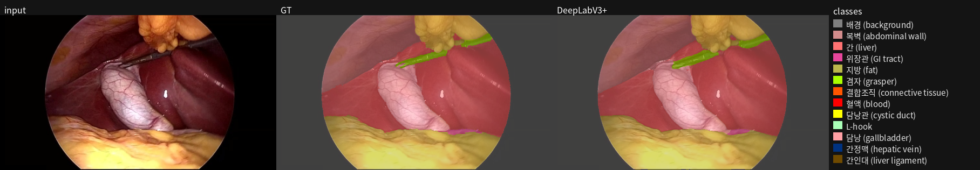


02.jpg
  mean_dice 0.946
  복벽 (abdominal wall)       dice 0.972  gt_px 35441
  간 (liver)                 dice 0.956  gt_px 19503
  지방 (fat)                  dice 0.975  gt_px 31038
  겸자 (grasper)              dice 0.893  gt_px 3859
  L-hook                    dice 0.940  gt_px 6714
  담낭 (gallbladder)          dice 0.939  gt_px 8593


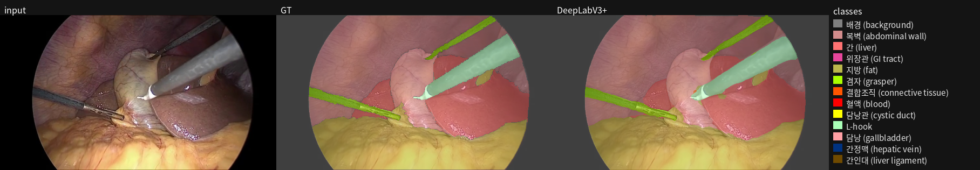


03.jpg
  mean_dice 0.859
  복벽 (abdominal wall)       dice 0.918  gt_px 8856
  간 (liver)                 dice 0.879  gt_px 29139
  지방 (fat)                  dice 0.657  gt_px 8207
  겸자 (grasper)              dice 0.899  gt_px 10639
  L-hook                    dice 0.946  gt_px 7504
  담낭 (gallbladder)          dice 0.854  gt_px 39743


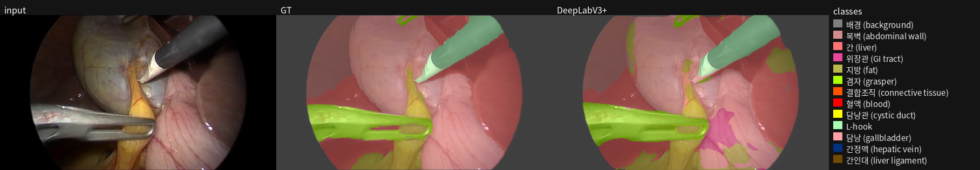

In [ ]:
import numpy as np
from pathlib import Path
import torch
from PIL import Image, ImageDraw, ImageFont
from torchvision.transforms.functional import normalize, to_tensor


# ── (1) 그림 도구 함수들 ────────────────────────────────────
def font_and_names(size):
    # 한글 폰트가 있으면 (한글 폰트, 한글 클래스 이름)을, 없으면 (영문 폰트, 영어 클래스 이름)을 돌려줍니다.
    # → 폰트가 없는 환경에서도 글자가 깨지지 않도록, 이름 표기를 폰트에 맞춰 바꾸는 것입니다.
    for path, index in (
        ("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc", 1),
        ("/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc", 1),
        ("/usr/share/fonts/truetype/nanum/NanumGothic.ttf", None),
        ("/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf", None),
    ):
        if not Path(path).exists():
            continue
        try:
            kw = {"index": index} if index is not None else {}
            return ImageFont.truetype(path, size, **kw), CLASS_LABEL
        except OSError:
            continue
    # 한글 폰트가 없으면 영문 폰트를 시도합니다.
    for path in (
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf",
    ):
        try:
            return ImageFont.truetype(path, size), CLASS_EN
        except OSError:
            continue
    return ImageFont.load_default(), CLASS_EN


def font(size):
    # 폰트 객체만 필요할 때 쓰는 간단 버전입니다. (이름 목록은 버립니다. `_` 는 '안 쓰는 값'이라는 관례입니다.)
    f, _ = font_and_names(size)
    return f


def caption(img, text):
    # 4번 셀의 caption 과 같은 역할로, 그림 위에 어두운 제목 줄을 붙입니다.
    # (이 버전은 img 가 이미 RGB 라고 가정해서 convert 과정이 없습니다.)
    bar_h = 28
    canvas = Image.new("RGB", (img.width, img.height + bar_h), (20, 20, 20))
    canvas.paste(img, (0, bar_h))
    draw = ImageDraw.Draw(canvas)
    draw.text((8, 6), text, fill=(255, 255, 255), font=font(16))
    return canvas


def legend_panel(height):
    # 클래스별 색 사각형과 이름을 세로로 나열한 '범례 패널'을 그립니다. (높이는 다른 그림에 맞춥니다.)
    f, names = font_and_names(15)
    title, _ = font_and_names(16)
    col_w = 280                                            # 범례 패널의 폭입니다.
    img = Image.new("RGB", (col_w, height), (20, 20, 20))
    draw = ImageDraw.Draw(img)
    draw.text((8, 8), "classes", fill=(255, 255, 255), font=title)
    gap = max(18, (height - 40) // NUM_CLASSES)            # 줄 간격입니다. (최소 18px)
    for i, name in enumerate(names):                       # enumerate : (번호, 이름) 쌍으로 꺼냅니다.
        y = 36 + i * gap
        c = tuple(int(v) for v in COLORS[i])               # i번 클래스의 색 (R, G, B)
        draw.rectangle([8, y, 24, y + 14], fill=c)         # 색 사각형
        draw.text((32, y - 2), name, fill=(230, 230, 230), font=f)   # 클래스 이름
    return img


# ── (2) 가중치 불러오기 (7번과 같은 방법) ──────────────────────
# 기본은 zip의 best.pt 입니다. 6번에서 학습한 가중치를 보려면 best_colab.pt 로 바꾸세요.
WEIGHTS = ROOT / "runs" / "best.pt"
print("weights", WEIGHTS)
ckpt = torch.load(WEIGHTS, map_location="cpu", weights_only=True)
size = tuple(ckpt.get("size", (512, 288)))         # 학습 때 쓴 입력 크기 (가로, 세로)
model = DeepLabV3Plus(num_classes=NUM_CLASSES, pretrained=False)
model.load_state_dict(ckpt["model"])
model.eval()
model.to(DEVICE)

# 결과 그림을 저장할 폴더입니다.
out_dir = ROOT / "runs" / "infer"
out_dir.mkdir(parents=True, exist_ok=True)

# ── (3) 예제 이미지마다 추론하고 그림 만들기 ─────────────────────
for path in sorted((ROOT / "examples").glob("[0-9][0-9].jpg")):
    raw = Image.open(path).convert("RGB")
    # ① 학습 때와 같은 크기로 줄입니다.
    img = raw.resize(size, Image.BILINEAR)
    # ② 텐서로 바꾸고 정규화한 뒤 GPU/CPU 로 보냅니다. 모양: (3, 288, 512)
    x = normalize(to_tensor(img), IMAGENET_MEAN, IMAGENET_STD).to(DEVICE)
    # ③~⑤ 추론입니다. no_grad : 기울기 계산 없이, unsqueeze(0) : (3,H,W) → (1,3,H,W) 로 배치 축을 붙입니다.
    #       argmax(dim=1) : 클래스 방향에서 점수가 가장 큰 번호를 고릅니다. [0] : 배치 축 제거 → (H, W)
    #       .cpu().numpy().astype(uint8) : 그림 도구가 쓰는 NumPy 배열(0~255 정수)로 변환합니다.
    with torch.no_grad():
        pred = model(x.unsqueeze(0)).argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
    # ⑥ 예측 마스크를 색칠해서 입력 이미지와 섞습니다. (overlay 는 4번 셀에서 정의했습니다.)
    pred_ov = overlay(img, pred)
    # 정답 마스크가 있으면 같은 크기로 줄여서 정답 그림도 만듭니다. (마스크는 NEAREST!)
    # 4번 셀과 달리 *_gt.jpg 는 쓰지 않고, 예측과 같은 방식(overlay)으로 직접 칠합니다.
    mask_path = path.parent / f"{path.stem}_mask.png"
    gt = None
    if mask_path.exists():
        gt = np.array(Image.open(mask_path).resize(size, Image.NEAREST), dtype=np.uint8)
        gt_panel = overlay(img, gt)
    else:
        gt_panel = img.copy()
    # 세 패널: 입력 | 정답 | 예측 (각각 제목 줄을 붙입니다.)
    panels = [
        caption(img, "input"),
        caption(gt_panel, "GT" if gt is not None else "GT missing"),
        caption(pred_ov, "DeepLabV3+"),
    ]
    # 패널 세 개와 범례 하나를 가로로 이어 붙인 큰 도화지를 만듭니다.
    w, h = panels[0].size
    leg = legend_panel(h)
    canvas = Image.new("RGB", (w * 3 + leg.width, h))
    for i, panel in enumerate(panels):
        canvas.paste(panel, (i * w, 0))
    canvas.paste(leg, (w * 3, 0))
    # 파일로 저장합니다. (JPEG 품질 92)
    out = out_dir / f"{path.stem}_pred.jpg"
    canvas.save(out, quality=92)
    print(path.name)
    # 정답이 있으면 이 한 장에 대한 클래스별 Dice 를 계산해서 출력합니다.
    if gt is not None:
        rows = []
        for c in range(1, NUM_CLASSES):
            p = pred == c                 # 예측이 c번인 픽셀
            t = gt == c                   # 정답이 c번인 픽셀
            tgt = int(t.sum())
            if tgt == 0:                  # 이 장에 정답이 없는 클래스는 건너뜁니다.
                continue
            den = int(p.sum()) + tgt
            # Dice = 2 × 겹침 / (예측 + 정답)
            d = (2 * int((p & t).sum()) / den) if den else 0.0
            rows.append((CLASS_LABEL[c], d, tgt))
        if rows:
            # mean_dice : 이 한 장에 정답이 있는 클래스만 평균한 값입니다. (테스트 전체 점수와는 다릅니다.)
            print(f"  mean_dice {sum(d for _, d, _ in rows) / len(rows):.3f}")
            for name, d, tgt in rows:
                print(f"  {name:24s}  dice {d:.3f}  gt_px {tgt}")
    show_img(canvas, width=980)
    print()

## 🎓 정리

### 이 노트북에서 배운 것

| 주제 | 핵심 내용 |
|---|---|
| **과제** | 세그멘테이션은 **픽셀마다 클래스를 분류**하는 일입니다. 정답은 클래스 번호로 채운 마스크입니다. |
| **모델** | DeepLabV3+ = **ResNet-50 인코더**(output stride 16, 마지막 단계는 dilation) → **ASPP**(다중 시야) → **디코더 + layer1 skip** |
| **학습** | 클래스 불균형 때문에 **클래스 가중치를 곱한 교차엔트로피 + Dice** 손실을 쓰고, **배경을 뺀 평균 Dice** 가 가장 높은 가중치를 저장합니다. |
| **평가** | 학습·선택에 쓰지 않은 **테스트 세트**에서 Dice·IoU를 구합니다. 클래스별로 따로 보고, 클래스 평균에는 클래스마다 한 번씩 동등하게 넣습니다. |
| **주의점** | 마스크는 **NEAREST**로 줄이고, 이미지와 마스크에는 **같은 기하 변환(좌우 반전)** 을 적용하며, 추론 전처리는 **학습과 동일**해야 합니다. |

### 💬 생각해 볼 질문

1. 7번의 표에서 Dice가 **가장 낮은 클래스**는 무엇인가요? 그 클래스는 (a) 크기가 작아서, (b) 다른 장기와 **색·질감이 비슷해서**, (c) 장면마다 **모양이 다양해서** 중 어디에 해당할까요?
2. 평균 Dice가 높은데도 실제 수술 보조에 **쓸 수 없는** 경우가 있다면 어떤 경우일까요? (힌트: 담낭관처럼 작지만 중요한 구조)
3. **검증 세트와 테스트 세트를 따로 두는 이유**는 무엇일까요? 검증 점수로 모델을 골랐다면, 그 점수를 최종 성능이라고 불러도 될까요?
4. 마스크를 줄일 때 BILINEAR를 쓰면 어떤 문제가 생길까요? 6번의 주석에 나온 예를 떠올려 보세요.
5. **픽셀 정확도**(전체 픽셀 중 맞춘 비율)로 모델을 고르면 안 되는 이유를 배경 비율과 연결해서 설명해 보세요.
6. U-Net과 DeepLabV3+는 skip 연결을 **어떻게 다르게** 쓰나요? 각각 어떤 장단점이 있을까요?
7. 클래스 가중치를 끄고(`weight = None`) 다시 학습하면 작은 클래스의 Dice는 어떻게 달라질까요? 예상을 먼저 적고, 직접 실험해서 확인해 보세요.

### 🐍 코드에 자주 나오는 파이썬 문법 미니 사전

| 문법 | 예 | 뜻 |
|---|---|---|
| f-string 서식 | `f"{x:.3f}"` | 소수 셋째 자리까지 출력합니다. |
| | `f"{n:03d}"` | 3자리 정수로, 빈칸은 0으로 채웁니다. (`007`) |
| | `f"{name:24s}"` | 문자열을 24칸 폭으로 왼쪽 정렬합니다. |
| | `f"{p:.1%}"` | 비율을 퍼센트로, 소수 첫째 자리까지 출력합니다. |
| | `f"{n:,}"` | 천 단위마다 쉼표를 찍습니다. (`40,350,125`) |
| 리스트 컴프리헨션 | `[b(x) for b in branches]` | `branches`의 각 원소 `b`에 `b(x)`를 적용한 결과를 리스트로 만듭니다. |
| 언패킹 | `*[...]`, `**kw` | 리스트의 원소 / 딕셔너리의 항목을 풀어서 하나씩 전달합니다. |
| 삼항 표현식 | `a if 조건 else b` | 조건이 참이면 `a`, 아니면 `b`입니다. |
| 슬라이싱 | `dice[1:]`, `x.shape[-2:]` | 1번부터 끝까지 / 뒤에서 두 개를 가져옵니다. |
| `zip`, `enumerate` | `zip(a, b)`, `enumerate(names)` | 두 리스트를 짝지어 / 번호와 함께 꺼냅니다. |
| 데코레이터 | `@torch.no_grad()` | 함수 안에서 기울기 계산을 끕니다. |
| `with` 문 | `with torch.no_grad():` | 이 블록 안에서만 기울기 계산을 끕니다. |
| `.item()` | `loss.item()` | 값이 하나뿐인 텐서를 일반 파이썬 숫자로 바꿉니다. |
| `_` 변수 | `for x, y, _ in loader` | "쓰지 않는 값"을 받는 관례적인 이름입니다. |
| `Path` 경로 | `ROOT / "dataset"` | `/` 연산자로 폴더와 파일 이름을 이어 붙입니다. |

### 🛠️ 자주 만나는 문제와 해결

| 증상 | 원인 | 해결 |
|---|---|---|
| 출력이 `device cpu` | GPU 런타임을 선택하지 않았습니다. | **런타임 → 런타임 유형 변경 → T4 GPU** 를 선택하고 처음부터 다시 실행하세요. |
| 다운로드 실패, 권한 오류 | 공유 설정이 `링크가 있는 모든 사용자`가 아닙니다. | 드라이브에서 공유 설정을 바꾸고 `ZIP_URL`을 확인하세요. |
| `… 가 없다. zip 안에 과제 폴더가 있는지 확인한다.` | `TASK` 이름이 zip의 최상위 폴더와 다릅니다. | `TASK` 값을 실제 폴더 이름에 맞게 수정하세요. |
| `FileNotFoundError: …/best.pt` 또는 `…/train_img` | 압축이 제대로 풀리지 않았거나 폴더 구조가 다릅니다. | 3번의 폴더 구조와 비교해 보고, 3번 셀을 순서대로 다시 실행하세요. |
| 이미지의 한글이 `□`로 깨집니다. | 한글 폰트가 설치되지 않았습니다. | 2번의 `apt-get` 셀을 다시 실행하세요. |
| `NameError: name '…' is not defined` | 앞쪽 셀(특히 3·4·5번)을 건너뛰었습니다. | 위에서부터 순서대로 실행하세요. |
| `CUDA out of memory` | 배치가 너무 큽니다. | `BATCH` 를 줄이세요. (예: 2) 계속되면 런타임을 다시 시작하세요. |
| `Expected more than 1 value per channel when training` | 학습 데이터 수를 `BATCH`로 나눈 나머지가 1이라 **마지막 배치가 1장**이 되었습니다. (ASPP의 전역 평균 갈래에서 BatchNorm이 오류를 냅니다.) | `BATCH` 값을 바꾸거나 `DataLoader(…, drop_last=True)` 로 마지막 배치를 버리세요. |
| 6번 실행 후 `best_colab.pt`가 사라졌습니다. | 3번의 `rm -rf` 셀을 다시 실행했습니다. | 학습 결과를 드라이브로 복사해 두고, 3번 셀은 처음에만 실행하세요. |
| 런타임을 다시 시작했더니 파일이 없습니다. | `/content` 는 세션이 끝나면 비워집니다. | 3번(다운로드·압축 해제)부터 다시 실행하세요. |